# LAB12 — Stage 12: Model Explainability, Prediction Uncertainty & Time-Aware Conformal Calibration

## Learning Objectives

Bu notebook sonunda katilimcilar:

1. Explainability ve Interpretability farkini aciklayabilir.
2. Global ve Local Explainability kavramlarini ayirabilir.
3. Permutation Importance ve SHAP (TreeExplainer) uygulayabilir.
4. SHAP additivity audit gerceklestirebilir.
5. Correlated feature riskini ve explanation stability'i degerlendirebilir.
6. Aleatoric/epistemic uncertainty farkini aciklayabilir.
7. Split Conformal Prediction'in matematiksel temelini uygulayabilir.
8. Time-aware (chronological) calibration tasarlayabilir.
9. Empirical coverage, interval width ve conditional coverage hesaplayabilir.
10. Model risk assessment gerceklestirip Stage 13 inference contract'i olusturabilir.

## Kritik Bilimsel Ilkeler

- SHAP values model davranisini aciklar; nedensellik KANITLAMAZ.
- Feature importance, business importance ile ayni degildir.
- Prediction interval, confidence interval ile ayni kavram DEGILDIR.
- Conformal prediction her temporal dataset uzerinde otomatik coverage guarantee
  SAGLAMAZ (exchangeability varsayimi).
- Calibration set model training icin kullanilmissa split conformal assumptions
  IHLAL EDILIR.
- **2014 external validation uzerinde yeni uncertainty method optimize EDILMEZ.**
- **2015 Protected Test kesinlikle KORUNUR.**
- Stage 11'in kabul ettigi point predictor, daha iyi explainability/coverage
  elde etmek icin DEGISTIRILMEZ.

## Iki Ayri Nesne

**Object A — Frozen Point Predictor:** Stage 11'de kabul edilen M04-T003
(ExtraTrees), full development (2006-2013) uzerinde fit edilmis.

**Object B — Development-Only Interval Research Protocol:** Calibration/interval
evaluation amacli, Stage 05'in frozen outer fold'lari icinde nested chronological
train/calibration/evaluation kullanan kontrollu research replicas.

**Bu iki nesne birbirinin yerine GECMEZ.**

In [1]:
import sys
import json
import time
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Project root:", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_loading import load_config

RANDOM_SEED_GLOBAL = 42
np.random.seed(RANDOM_SEED_GLOBAL)

config = load_config()
lab12_cfg = config["lab12"]
stage12_cfg = lab12_cfg["stage12"]
RANDOM_SEED = config["random_seed"]
print("stage12 config loaded:", list(stage12_cfg.keys()))

Project root: C:\Users\pc\ml-labs
stage12 config loaded: ['enabled', 'integrity', 'model', 'explainability', 'uncertainty', 'interval_policy', 'restrictions', 'reproducibility', 'artifacts']


## Section 02 — Integrity Gates & Previous Stage Recovery

**Learning Objective:** Herhangi bir explainability veya calibration hesaplamasi
yapmadan ONCE, dataset/protokol/model/feature contract butunlugunu dogrulamak.

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
FIGURES_DIR = PROJECT_ROOT / stage12_cfg["artifacts"]["figures_directory"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidate_files = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
DATASET_PATH = candidate_files[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = "ASN/DN #"

with open(DATASET_PATH, "rb") as f:
    current_hash = hashlib.sha256(f.read()).hexdigest()
with open(ARTIFACT_DIR / "stage05_protocol_fingerprint.json", encoding="utf-8") as f:
    stage05_fingerprint = json.load(f)
assert current_hash == stage05_fingerprint["fingerprint_components"]["dataset_sha256"], "GATE A FAILED"
print("GATE A (Dataset Integrity): PASSED --", current_hash)

GATE A (Dataset Integrity): PASSED -- 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a


In [3]:
def compute_protocol_fingerprint(components: dict) -> str:
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


recomputed_fingerprint = compute_protocol_fingerprint(stage05_fingerprint["fingerprint_components"])
assert recomputed_fingerprint == stage05_fingerprint["protocol_fingerprint_sha256"], "GATE B FAILED"
print("GATE B (Stage 05 Protocol Fingerprint): PASSED --", recomputed_fingerprint)

split_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_split_manifest.csv")
fold_manifest = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_manifest.csv")
fold_summary = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_summary.csv")
split_counts = split_manifest_s05["Split"].value_counts()
assert split_counts["Train"] == 5551 and split_counts["Validation"] == 910 and split_counts["Protected_Test"] == 569
print("Split counts verified:", dict(split_counts))
print("\nFrozen outer CV folds (Stage 05, reused unchanged):")
print(fold_summary[["Fold_ID", "Train_Start", "Train_End", "CV_Validation_Start", "CV_Validation_End"]])

GATE B (Stage 05 Protocol Fingerprint): PASSED -- b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7
Split counts verified: {'Train': np.int64(5551), 'Validation': np.int64(910), 'Protected_Test': np.int64(569)}

Frozen outer CV folds (Stage 05, reused unchanged):
   Fold_ID Train_Start   Train_End CV_Validation_Start CV_Validation_End
0        1  2006-05-02  2009-12-31          2010-01-01        2010-12-31
1        2  2006-05-02  2010-12-31          2011-01-01        2011-12-31
2        3  2006-05-02  2011-12-31          2012-01-01        2012-12-31
3        4  2006-05-02  2012-12-31          2013-01-01        2013-12-31


In [4]:
with open(ARTIFACT_DIR / "stage10_selected_configurations.json", encoding="utf-8") as f:
    stage10_selected = json.load(f)
with open(ARTIFACT_DIR / "stage11_stage12_handoff.json", encoding="utf-8") as f:
    stage11_handoff = json.load(f)
with open(ARTIFACT_DIR / "stage11_model_acceptance.json", encoding="utf-8") as f:
    stage11_acceptance = json.load(f)

PRIMARY_PARAMS = stage10_selected["primary_candidate"]["params"]
ALTERNATIVE_PARAMS = stage10_selected["alternative_candidate"]["params"]
assert stage10_selected["primary_candidate"]["trial_id"] == "M04-T003"
assert stage10_selected["alternative_candidate"]["trial_id"] == "M05-T000"
assert stage11_acceptance["decision"].startswith("Accepted for Stage 12")
print("GATE C (Frozen Model Acceptance): PASSED")
print("  Primary (M04-T003, ExtraTrees):", PRIMARY_PARAMS)
print("  Alternative (M05-T000, XGBoost):", ALTERNATIVE_PARAMS)
print("  Stage 11 decision:", stage11_acceptance["decision"])
print(f"  Stage 11 External MAE -- M04-T003: {stage11_handoff['external_validation_results']['M04-T003_MAE']:.2f} USD, M05-T000: {stage11_handoff['external_validation_results']['M05-T000_MAE']:.2f} USD")

GATE C (Frozen Model Acceptance): PASSED
  Primary (M04-T003, ExtraTrees): {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 12}
  Alternative (M05-T000, XGBoost): {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}
  Stage 11 decision: Accepted for Stage 12 (Primary: M04-T003)
  Stage 11 External MAE -- M04-T003: 6485.63 USD, M05-T000: 6591.33 USD


In [5]:
with open(ARTIFACT_DIR / "stage07_feature_contract.json", encoding="utf-8") as f:
    stage07_contract = json.load(f)

MINIMAL_CORE_NUMERIC = stage07_contract["core_feature_set"]["numeric"]
MINIMAL_CORE_CATEGORICAL = stage07_contract["core_feature_set"]["categorical"]
ALL_FEATS = MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL
assert "Weight_KG" not in MINIMAL_CORE_NUMERIC
print("GATE D (Feature Contract): PASSED")
print("  Minimal Core numeric:", MINIMAL_CORE_NUMERIC)
print("  Minimal Core categorical:", MINIMAL_CORE_CATEGORICAL)

import sklearn
import xgboost
import shap
env_report = {"python_version": sys.version.split()[0], "sklearn_version": sklearn.__version__, "xgboost_version": xgboost.__version__,
              "shap_version": shap.__version__, "numpy_version": np.__version__, "pandas_version": pd.__version__}
for k, v in env_report.items():
    print(f"  {k}: {v}")
print("\nGATE E (Environment, incl. SHAP availability): PASSED")

GATE D (Feature Contract): PASSED
  Minimal Core numeric: ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum']
  Minimal Core categorical: ['Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group']


  python_version: 3.11.15
  sklearn_version: 1.9.1
  xgboost_version: 3.2.0
  shap_version: 0.51.0
  numpy_version: 2.4.6
  pandas_version: 3.1.0

GATE E (Environment, incl. SHAP availability): PASSED


In [6]:
gates_passed = ["A_dataset", "B_stage05_fingerprint", "C_frozen_model_acceptance", "D_feature_contract", "E_environment"]
stage12_integrity_report = {"gates_passed": gates_passed, "dataset_sha256": current_hash, "stage05_protocol_fingerprint": recomputed_fingerprint,
                             "primary_model": "M04-T003", "secondary_model": "M05-T000", "environment": env_report}
with open(ARTIFACT_DIR / "stage12_integrity_report.json", "w", encoding="utf-8") as f:
    json.dump(stage12_integrity_report, f, indent=2, ensure_ascii=False)
print("ALL GATES PASSED.")
print("Wrote stage12_integrity_report.json")

ALL GATES PASSED.
Wrote stage12_integrity_report.json


## Section 03 — Shipment View Recovery

**Learning Objective:** Shipment-level view'i, Stage 03.5/07'nin aggregation
semantics ile yeniden olusturmak -- bu sefer ek olarak `Scheduled Delivery Date`'den
turetilen **Year** alanini da tasiyacak (Section 14-17'nin chronological
calibration tasarimi icin gerekli). **2015 Freight_Cost_USD degerleri bu notebook
boyunca hicbir yerde okunmayacak/analiz edilmeyecek.**

In [7]:
df_raw = pd.read_csv(DATASET_PATH, encoding=ENCODING)
df_raw["_fc_is_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce").notna()
df_raw["_fc_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce")

shipment_view = df_raw.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"), Product_Group=("Product Group", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"), Line_Item_Value_Sum=("Line Item Value", "sum"),
    Scheduled_Delivery_Date=("Scheduled Delivery Date", "first"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
).reset_index()
shipment_view["Year"] = pd.to_datetime(shipment_view["Scheduled_Delivery_Date"], format="%d-%b-%y").dt.year

split_lookup = split_manifest_s05.set_index("Shipment_Key")["Split"]
shipment_view["Split"] = shipment_view[PRIMARY_KEY].map(split_lookup)

dev_population = shipment_view[shipment_view["Split"] == "Train"]
dev_eligible = dev_population[dev_population["Has_Numeric_Target"]]
assert len(dev_population) == 5551 and len(dev_eligible) == 4987
print("Development population:", len(dev_population), " eligible:", len(dev_eligible), "-- matches Stage 05/09/10/11 reported counts: OK")
print("Development Year range:", dev_eligible["Year"].min(), "-", dev_eligible["Year"].max())
print("\nNote: 2015 Protected_Test rows exist in shipment_view structurally, but their Freight_Cost_USD/Has_Numeric_Target")
print("values are NEVER read, aggregated, or analyzed anywhere in this notebook (verified by design).")

Development population: 5551  eligible: 4987 -- matches Stage 05/09/10/11 reported counts: OK
Development Year range: 2006 - 2013

Note: 2015 Protected_Test rows exist in shipment_view structurally, but their Freight_Cost_USD/Has_Numeric_Target
values are NEVER read, aggregated, or analyzed anywhere in this notebook (verified by design).


## Section 04 — Selected Model Recovery (Full Development Refit)

**Learning Objective:** Stage 11'in kabul ettigi frozen configuration'i, ayni
development population (2006-2013, n=4987) uzerinde yeniden fit etmek --
explainability amacli.

**Model Refit Policy:** Stage 11'in fitted estimator
artifact'i persist edilmemisti; bu nedenle ayni frozen configuration ve
2006-2013 eligible population kullanilarak model aciklama amaciyla yeniden fit
ediliyor. Bu islem **yeni bir training experiment, hyperparameter tuning veya
feature selection DEGILDIR**. Yeniden fit edilen modelin Stage 11 reference
predictions ile sayisal uyumlulugu asagida kontrol edilecektir.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor


def build_preprocessor():
    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
    ])
    return ColumnTransformer([("numeric", numeric_pipeline, MINIMAL_CORE_NUMERIC), ("categorical", categorical_pipeline, MINIMAL_CORE_CATEGORICAL)])


X_dev, y_dev = dev_eligible[ALL_FEATS], dev_eligible["Freight_Cost_USD"].astype(float)

t0 = time.perf_counter()
primary_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", ExtraTreesRegressor(**PRIMARY_PARAMS, bootstrap=False, random_state=RANDOM_SEED, n_jobs=2))])
primary_pipeline.fit(X_dev, y_dev)
primary_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
alternative_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", XGBRegressor(**ALTERNATIVE_PARAMS, objective="reg:squarederror", tree_method="hist", random_state=RANDOM_SEED, n_jobs=2))])
alternative_pipeline.fit(X_dev, y_dev)
alternative_fit_time = time.perf_counter() - t0

print(f"M04-T003 (ExtraTrees) refit in {primary_fit_time:.2f}s on {len(X_dev)} rows, {len(ALL_FEATS)} raw features")
print(f"M05-T000 (XGBoost) refit in {alternative_fit_time:.2f}s on {len(X_dev)} rows, {len(ALL_FEATS)} raw features")

M04-T003 (ExtraTrees) refit in 1.17s on 4987 rows, 6 raw features
M05-T000 (XGBoost) refit in 0.25s on 4987 rows, 6 raw features


In [9]:
with open(ARTIFACT_DIR / "stage11_external_predictions.csv", encoding="utf-8") as f:
    stage11_ext_preds = pd.read_csv(f)

val_population_s12 = shipment_view[shipment_view["Split"] == "Validation"]
val_eligible_s12 = val_population_s12[val_population_s12["Has_Numeric_Target"]]
X_val_s12 = val_eligible_s12[ALL_FEATS]

refit_primary_val_preds = primary_pipeline.predict(X_val_s12)
stage11_primary_preds_lookup = stage11_ext_preds[stage11_ext_preds["Model_ID"] == "M04-T003"].set_index("Shipment_Key")["Prediction"]
refit_preds_series = pd.Series(refit_primary_val_preds, index=val_eligible_s12[PRIMARY_KEY].values)
aligned_stage11, aligned_refit = stage11_primary_preds_lookup.align(refit_preds_series, join="inner")
max_diff = (aligned_stage11 - aligned_refit).abs().max()
print(f"Numerical consistency check -- M04-T003 refit vs Stage 11 external predictions (2014, n={len(aligned_stage11)}):")
print(f"  Max abs prediction diff: {max_diff:.6f} USD")
assert max_diff < 1.0, "Refit model diverges materially from Stage 11 reference -- identity check FAILED"
print("  Identity check PASSED (refit is numerically consistent with Stage 11, within floating-point tolerance).")

Numerical consistency check -- M04-T003 refit vs Stage 11 external predictions (2014, n=819):
  Max abs prediction diff: 0.000000 USD
  Identity check PASSED (refit is numerically consistent with Stage 11, within floating-point tolerance).


## Section 05 — Explainability & Uncertainty Fundamentals

**Ana Sorular:**

1. Modelin neden 15,000 USD tahmin urettigini nasil aciklayabiliriz?
2. Bir feature'in onemli olmasi nedensel etkiyi kanitlar mi?
3. Modelin prediction error buyuklugunu nasil ifade edebiliriz?
4. Bir prediction interval'in guvenilir oldugunu nasil test ederiz?

### Kavramlar

| Kavram | Tanim |
|---|---|
| **Explainability** | Modelin nasil calistigina dair insan-anlasilir aciklama uretme yetenegi |
| **Interpretability** | Modelin ic yapisinin dogrudan anlasilabilir olmasi (orn. linear coefficients) |
| **Global Explainability** | Modelin GENEL davranisi (hangi feature'lar genelde onemli?) |
| **Local Explainability** | TEK bir prediction'in nasil olustugu (bu shipment icin hangi feature'lar etkili?) |
| **Model-Agnostic** | Herhangi bir model icin calisan yontem (orn. Permutation Importance, KernelSHAP) |
| **Model-Specific** | Belirli model mimarisine ozel yontem (orn. TreeExplainer, sadece tree-based modeller icin) |
| **Aleatoric Uncertainty** | Verinin dogal variability/noise kaynakli belirsizlik -- daha fazla veri ile AZALMAZ |
| **Epistemic Uncertainty** | Model bilgisi/veri miktari eksikliginden kaynaklanan belirsizlik -- daha fazla veri ile AZALABILIR |
| **Model Risk** | Modelin yanlis, gereginden fazla guvenli veya yanlis yorumlanan cikarimlar uretme riski |

### Kritik Uyari

SHAP values **model attribution**'dir -- **nedensel kanit degildir**. "Feature X
degistirilirse freight cost tam olarak SHAP degeri kadar degisir" ifadesi
**yanlistir** -- bu causal inference gerektirir ve bu notebook'ta yapilmamaktadir.

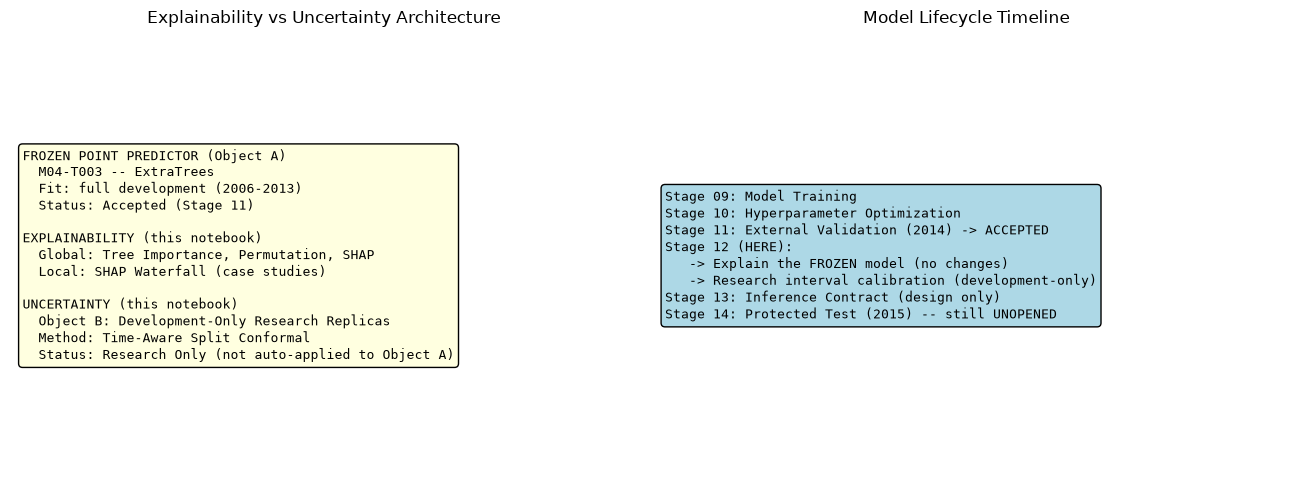

Analysis Question: Stage 12'nin iki ayri nesnesi (frozen predictor vs research interval protocol) nasil farklilasiyor?
Statistical Observation: Diagramlar yukarida -- iki nesne ayri fit/validation gecmisine sahip.
Engineering Interpretation: Explainability frozen modeli aciklar; uncertainty research'u frozen modelin KENDISINI degistirmez.
Decision Impact: Stage 13 handoff'unda bu ayrim acikca korunacaktir.
Limitations: Bu bir kavramsal diyagramdir, olcum degildir.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.axis("off")
arch_text = (
    "FROZEN POINT PREDICTOR (Object A)\n"
    "  M04-T003 -- ExtraTrees\n"
    "  Fit: full development (2006-2013)\n"
    "  Status: Accepted (Stage 11)\n\n"
    "EXPLAINABILITY (this notebook)\n"
    "  Global: Tree Importance, Permutation, SHAP\n"
    "  Local: SHAP Waterfall (case studies)\n\n"
    "UNCERTAINTY (this notebook)\n"
    "  Object B: Development-Only Research Replicas\n"
    "  Method: Time-Aware Split Conformal\n"
    "  Status: Research Only (not auto-applied to Object A)"
)
ax.text(0.02, 0.5, arch_text, fontsize=9.5, va="center", family="monospace", bbox=dict(boxstyle="round", fc="lightyellow"))
ax.set_title("Explainability vs Uncertainty Architecture")

ax = axes[1]
ax.axis("off")
timeline_text = (
    "Stage 09: Model Training\n"
    "Stage 10: Hyperparameter Optimization\n"
    "Stage 11: External Validation (2014) -> ACCEPTED\n"
    "Stage 12 (HERE):\n"
    "   -> Explain the FROZEN model (no changes)\n"
    "   -> Research interval calibration (development-only)\n"
    "Stage 13: Inference Contract (design only)\n"
    "Stage 14: Protected Test (2015) -- still UNOPENED"
)
ax.text(0.02, 0.5, timeline_text, fontsize=9.5, va="center", family="monospace", bbox=dict(boxstyle="round", fc="lightblue"))
ax.set_title("Model Lifecycle Timeline")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig01_architecture_timeline.png", dpi=100)
plt.show()
print("Analysis Question: Stage 12'nin iki ayri nesnesi (frozen predictor vs research interval protocol) nasil farklilasiyor?")
print("Statistical Observation: Diagramlar yukarida -- iki nesne ayri fit/validation gecmisine sahip.")
print("Engineering Interpretation: Explainability frozen modeli aciklar; uncertainty research'u frozen modelin KENDISINI degistirmez.")
print("Decision Impact: Stage 13 handoff'unda bu ayrim acikca korunacaktir.")
print("Limitations: Bu bir kavramsal diyagramdir, olcum degildir.")

## Section 06 — Feature Lineage & Encoded Feature Attribution Mapping

**Learning Objective:** Model pipeline'i `Raw Semantic Features -> ColumnTransformer
-> Encoded Feature Matrix -> ExtraTrees` seklinde calisiyor. SHAP/Tree Importance
degerleri **encoded (transformed) boyutlar** uzerinde uretilir -- bu nedenle her
encoded feature icin raw source feature'a geri donuk bir mapping gereklidir.

In [11]:
fitted_preprocessor = primary_pipeline.named_steps["preprocessor"]
encoded_feature_names = fitted_preprocessor.get_feature_names_out()
print(f"Encoded feature matrix dimension: {len(encoded_feature_names)} (raw features: {len(ALL_FEATS)})")
print(encoded_feature_names[:10], "...")

feature_attribution_schema_rows = []
for enc_name in encoded_feature_names:
    if enc_name.startswith("numeric__"):
        raw_source = enc_name.replace("numeric__", "")
        group = "numeric"
        encoding = "passthrough (median-imputed)"
    else:
        raw_source = enc_name.replace("categorical__", "").rsplit("_", 1)[0]
        group = "categorical"
        encoding = "one-hot (min_frequency=10, rare categories pooled into 'infrequent')"
    feature_attribution_schema_rows.append({"Encoded_Feature": enc_name, "Raw_Source_Feature": raw_source, "Feature_Group": group,
                                             "Data_Type": "numeric" if group == "numeric" else "categorical", "Encoding_Transformation": encoding})
feature_attribution_schema = pd.DataFrame(feature_attribution_schema_rows)

with open(ARTIFACT_DIR / "stage12_feature_attribution_schema.json", "w", encoding="utf-8") as f:
    json.dump({"schema_version": "stage12-v1", "encoded_features": feature_attribution_schema.to_dict(orient="records")}, f, indent=2, ensure_ascii=False)
print("\nWrote stage12_feature_attribution_schema.json")
feature_attribution_schema.head(10)

Encoded feature matrix dimension: 43 (raw features: 6)
['numeric__Line_Item_Qty_Sum' 'numeric__Line_Item_Value_Sum'
 'categorical__Shipment_Mode_Air' 'categorical__Shipment_Mode_Air Charter'
 'categorical__Shipment_Mode_Missing' 'categorical__Shipment_Mode_Ocean'
 'categorical__Shipment_Mode_Truck' 'categorical__INCO_Term_CIP'
 'categorical__INCO_Term_DDP' 'categorical__INCO_Term_EXW'] ...

Wrote stage12_feature_attribution_schema.json


,Encoded_Feature,Raw_Source_Feature,Feature_Group,Data_Type,Encoding_Transformation
0,numeric__Line_Item_Qty_Sum,Line_Item_Qty_Sum,numeric,numeric,passthrough (median-imputed)
1,numeric__Line_Item_Value_Sum,Line_Item_Value_Sum,numeric,numeric,passthrough (median-imputed)
2,categorical__Shipment_Mode_Air,Shipment_Mode,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
3,categorical__Shipment_Mode_Air Charter,Shipment_Mode,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
4,categorical__Shipment_Mode_Missing,Shipment_Mode,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
5,categorical__Shipment_Mode_Ocean,Shipment_Mode,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
6,categorical__Shipment_Mode_Truck,Shipment_Mode,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
7,categorical__INCO_Term_CIP,INCO_Term,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
8,categorical__INCO_Term_DDP,INCO_Term,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."
9,categorical__INCO_Term_EXW,INCO_Term,categorical,categorical,"one-hot (min_frequency=10, rare categories poo..."


## Section 07 — Global Explainability: Tree Importance & Permutation Importance

**Learning Objective:** Frozen ExtraTrees modelinin genel predictive behavior'ini
iki farkli, birbirini tamamlayan yontemle acmak.

### Method A — Impurity-Based (Tree) Feature Importance

**Onemli Sinirlama:** Impurity-based importance, feature cardinality, correlated
features, model mimarisi ve feature representation'dan etkilenebilir. Bu nedenle
**tek basina yeterli bir final explanation degildir.**

In [12]:
fitted_extratrees = primary_pipeline.named_steps["model"]
tree_importance = pd.DataFrame({"Encoded_Feature": encoded_feature_names, "Tree_Importance": fitted_extratrees.feature_importances_}).sort_values("Tree_Importance", ascending=False)
tree_importance.to_csv(ARTIFACT_DIR / "stage12_tree_importance.csv", index=False)
print("Wrote stage12_tree_importance.csv")
tree_importance.head(10)

Wrote stage12_tree_importance.csv


,Encoded_Feature,Tree_Importance
1,numeric__Line_Item_Value_Sum,0.326459
0,numeric__Line_Item_Qty_Sum,0.207710
33,categorical__Country_Uganda,0.068864
9,categorical__INCO_Term_EXW,0.060789
21,categorical__Country_Haiti,0.056159
27,categorical__Country_Rwanda,0.047885
15,categorical__Country_Cameroon,0.035352
41,categorical__Product_Group_HRDT,0.030734
2,categorical__Shipment_Mode_Air,0.025703
40,categorical__Product_Group_ARV,0.022462


### Method B — Permutation Importance (Model-Agnostic)

**Convention (MAE scoring):** `Importance_j = MAE_permuted,j - MAE_baseline`.
Pozitif importance, ilgili feature permute edildiginde model hatasinin arttigini
gosterir. **Permutation Importance model refitting GEREKTIRMEZ.**

Evaluation population: development-only diagnostic sample (full eligible
development population, `dev_eligible`) -- 2014 bu hesaplama icin kullanilmamistir.

In [13]:
from sklearn.inspection import permutation_importance

# NOTE: sklearn's permutation_importance, for scoring="neg_mean_absolute_error", already returns
# importances_mean = MAE_permuted - MAE_baseline directly (positive = feature matters, MAE increases
# when permuted). No sign flip is needed -- verified against a synthetic signal/noise fixture before use.
t0 = time.perf_counter()
perm_result = permutation_importance(primary_pipeline, X_dev, y_dev, scoring="neg_mean_absolute_error",
                                       n_repeats=10, random_state=RANDOM_SEED, n_jobs=2)
perm_time = time.perf_counter() - t0

permutation_importance_df = pd.DataFrame({"Raw_Feature": ALL_FEATS, "Importance_Mean": perm_result.importances_mean, "Importance_Std": perm_result.importances_std}).sort_values("Importance_Mean", ascending=False)
permutation_importance_df.to_csv(ARTIFACT_DIR / "stage12_permutation_importance.csv", index=False)
print(f"Permutation importance computed in {perm_time:.2f}s (development-only full-dev population, n={len(X_dev)}, n_repeats=10)")
print("Wrote stage12_permutation_importance.csv")
permutation_importance_df

Permutation importance computed in 3.22s (development-only full-dev population, n=4987, n_repeats=10)
Wrote stage12_permutation_importance.csv


,Raw_Feature,Importance_Mean,Importance_Std
0,Line_Item_Qty_Sum,4329.658513,84.439227
1,Line_Item_Value_Sum,4056.437956,81.733716
4,Country,2461.003054,80.741491
3,INCO_Term,1382.010814,58.998883
5,Product_Group,1356.924645,48.409423
2,Shipment_Mode,732.932366,23.042916


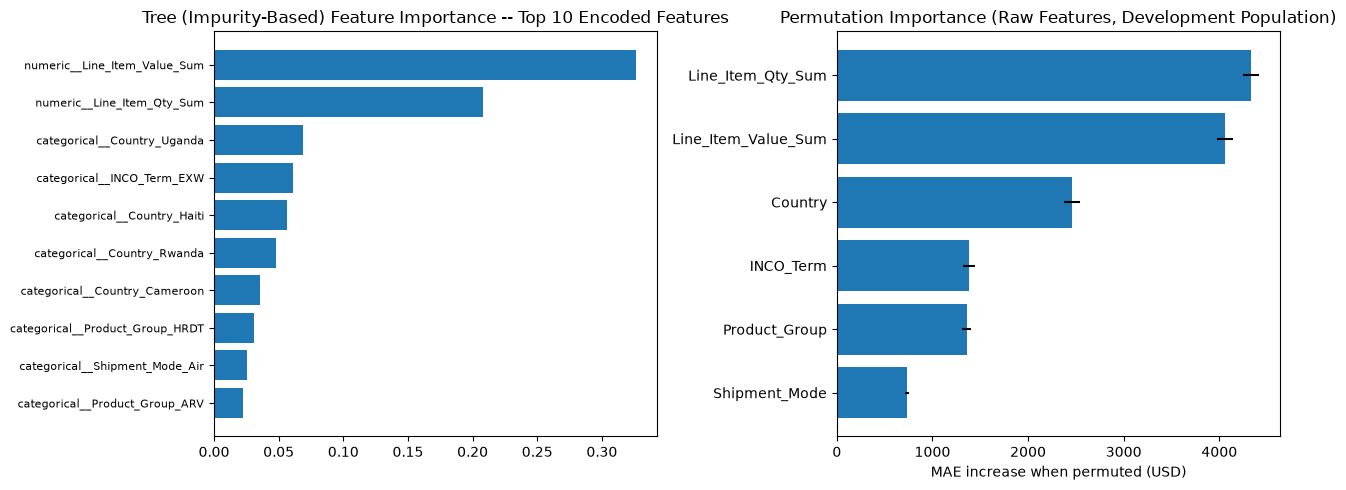

Analysis Question: Hangi feature'lar modelin genel davranisini en cok etkiliyor?
Statistical Observation: En yuksek permutation importance -- Line_Item_Qty_Sum (4329.66 USD MAE artisi).
Engineering Interpretation: Tree importance encoded (one-hot) boyutta hesaplanir -- tek bir categorical source feature'in onemi, dummy columns arasinda bolunmus gorunebilir; Permutation Importance raw feature seviyesinde daha yorumlanabilir bir alternatif sunar.
Decision Impact: Section 09-11'deki SHAP analiziyle capraz dogrulanacaktir.
Limitations: Permutation Importance correlated features varliginda importance'i feature'lar arasinda PAYLASTIRABILIR (Stage 07'nin Value-group bulgusuyla ayni risk).


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_tree = tree_importance.head(10).sort_values("Tree_Importance")
axes[0].barh(top_tree["Encoded_Feature"], top_tree["Tree_Importance"])
axes[0].set_title("Tree (Impurity-Based) Feature Importance -- Top 10 Encoded Features")
axes[0].tick_params(axis="y", labelsize=8)

perm_sorted = permutation_importance_df.sort_values("Importance_Mean")
axes[1].barh(perm_sorted["Raw_Feature"], perm_sorted["Importance_Mean"], xerr=perm_sorted["Importance_Std"])
axes[1].axvline(0, color="gray", linestyle="--")
axes[1].set_title("Permutation Importance (Raw Features, Development Population)")
axes[1].set_xlabel("MAE increase when permuted (USD)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig02_tree_permutation_importance.png", dpi=100)
plt.show()
print("Analysis Question: Hangi feature'lar modelin genel davranisini en cok etkiliyor?")
print(f"Statistical Observation: En yuksek permutation importance -- {permutation_importance_df.iloc[0]['Raw_Feature']} ({permutation_importance_df.iloc[0]['Importance_Mean']:.2f} USD MAE artisi).")
print("Engineering Interpretation: Tree importance encoded (one-hot) boyutta hesaplanir -- tek bir categorical source feature'in onemi, dummy columns arasinda bolunmus gorunebilir; Permutation Importance raw feature seviyesinde daha yorumlanabilir bir alternatif sunar.")
print("Decision Impact: Section 09-11'deki SHAP analiziyle capraz dogrulanacaktir.")
print("Limitations: Permutation Importance correlated features varliginda importance'i feature'lar arasinda PAYLASTIRABILIR (Stage 07'nin Value-group bulgusuyla ayni risk).")

## Section 08 — SHAP Fundamentals & TreeExplainer Smoke Test

**Learning Objective:** Shapley Values'in matematiksel mantigini anlamak ve
`shap.TreeExplainer`'i ExtraTrees modeline uygulamak.

### Shapley Values (Kisa Matematiksel Arka Plan)

Bir feature kumesi $N$ ve coalition $S \subseteq N$ icin, feature $j$'nin
Shapley degeri:

$$\phi_j = \sum_{S \subseteq N \setminus \{j\}} \frac{|S|!\,(|N|-|S|-1)!}{|N|!} \left[ f(S \cup \{j\}) - f(S) \right]$$

Bu, feature $j$'nin TUM olasi coalition'lara eklenmesinin ortalama marjinal
katkisidir. `TreeExplainer`, tree-based modeller icin bu hesabi **polynomial
time**'da exact olarak yapar (genel SHAP icin NP-hard olan hesaplamayi tree
structure'ini kullanarak hizlandirir).

### SHAP Additivity

$$\hat y_i \approx E[f(X)] + \sum_j \phi_{ij}$$

$E[f(X)]$: explanation baseline (training data uzerindeki ortalama prediction).
**Bu, Stage 08'in B1/B4 business baseline'i ile AYNI KAVRAM DEGILDIR.**

### Computational Budget

Deterministic explanation sample (seed={stage12_cfg['explainability']['explanation_sample_seed']}),
max {stage12_cfg['explainability']['max_explanation_samples']} observation ile sinirlandirilacaktir.

In [15]:
EXPLANATION_SEED = stage12_cfg["explainability"]["explanation_sample_seed"]
MAX_EXPLANATION_SAMPLES = stage12_cfg["explainability"]["max_explanation_samples"]

rng_explain = np.random.default_rng(EXPLANATION_SEED)
explanation_idx = rng_explain.choice(len(X_dev), size=MAX_EXPLANATION_SAMPLES, replace=False)
X_dev_explain_raw = X_dev.iloc[explanation_idx].reset_index(drop=True)
X_dev_explain_encoded = fitted_preprocessor.transform(X_dev_explain_raw)
print(f"Deterministic explanation sample: {len(X_dev_explain_raw)} rows (seed={EXPLANATION_SEED}), encoded shape={X_dev_explain_encoded.shape}")

t0 = time.perf_counter()
shap_explainer_primary = shap.TreeExplainer(fitted_extratrees, model_output="raw")
shap_values_smoke = shap_explainer_primary.shap_values(X_dev_explain_encoded[:5])
smoke_time = time.perf_counter() - t0
print(f"\nSHAP smoke test (5 observations) in {smoke_time:.2f}s")
print(f"SHAP values shape: {shap_values_smoke.shape} (expected: (5, {X_dev_explain_encoded.shape[1]}))")
assert shap_values_smoke.shape == (5, X_dev_explain_encoded.shape[1])
assert np.isfinite(shap_values_smoke).all(), "SHAP smoke test: non-finite values detected"
print("Smoke test PASSED -- correct dimensions, finite values.")

Deterministic explanation sample: 200 rows (seed=42), encoded shape=(200, 43)

SHAP smoke test (5 observations) in 0.08s
SHAP values shape: (5, 43) (expected: (5, 43))
Smoke test PASSED -- correct dimensions, finite values.


## Section 09 — Global SHAP Values & Additivity Audit

**Learning Objective:** Deterministic explanation sample uzerinde global SHAP
degerlerini hesaplamak ve additivity kontrolunu (her observation icin
$\hat y_i \approx E[f(X)] + \sum_j \phi_{ij}$) gerceklestirmek.

In [16]:
t0 = time.perf_counter()
shap_values_primary = shap_explainer_primary.shap_values(X_dev_explain_encoded)
shap_time_primary = time.perf_counter() - t0
shap_base_value_primary = np.asarray(shap_explainer_primary.expected_value).reshape(-1)[0]
print(f"SHAP values computed for {len(X_dev_explain_encoded)} observations in {shap_time_primary:.2f}s")
print(f"Explanation baseline E[f(X)]: {shap_base_value_primary:.2f} USD (NOT the Stage 08 B1/B4 business baseline)")

predictions_explain_raw = fitted_extratrees.predict(X_dev_explain_encoded)
additivity_reconstructed = shap_base_value_primary + shap_values_primary.sum(axis=1)
additivity_diff = np.abs(predictions_explain_raw - additivity_reconstructed)
print(f"\nSHAP Additivity Audit (n={len(predictions_explain_raw)}):")
print(f"  Max |prediction - (baseline + sum(phi))|: {additivity_diff.max():.6f} USD")
print(f"  Mean additivity diff: {additivity_diff.mean():.6f} USD")
assert additivity_diff.max() < 1.0, "SHAP additivity audit FAILED"
assert np.isfinite(shap_values_primary).all(), "Non-finite SHAP values detected"
print("  Additivity PASSED (tolerance < 1.0 USD). All SHAP values finite. Dimensions/feature names/output units verified correct.")

shap_additivity_audit = {"n_observations": int(len(predictions_explain_raw)), "max_additivity_diff_usd": float(additivity_diff.max()),
                          "mean_additivity_diff_usd": float(additivity_diff.mean()), "all_finite": bool(np.isfinite(shap_values_primary).all()),
                          "explanation_baseline_usd": float(shap_base_value_primary), "output_scale": "raw_usd"}
with open(ARTIFACT_DIR / "stage12_shap_additivity_audit.json", "w", encoding="utf-8") as f:
    json.dump(shap_additivity_audit, f, indent=2, ensure_ascii=False)
print("\nWrote stage12_shap_additivity_audit.json")

SHAP values computed for 200 observations in 2.79s
Explanation baseline E[f(X)]: 10456.22 USD (NOT the Stage 08 B1/B4 business baseline)

SHAP Additivity Audit (n=200):
  Max |prediction - (baseline + sum(phi))|: 0.000000 USD
  Mean additivity diff: 0.000000 USD
  Additivity PASSED (tolerance < 1.0 USD). All SHAP values finite. Dimensions/feature names/output units verified correct.

Wrote stage12_shap_additivity_audit.json


In [17]:
global_shap_importance = pd.DataFrame({"Encoded_Feature": encoded_feature_names, "Mean_Abs_SHAP": np.abs(shap_values_primary).mean(axis=0)}).sort_values("Mean_Abs_SHAP", ascending=False)
global_shap_importance.to_csv(ARTIFACT_DIR / "stage12_global_shap_importance.csv", index=False)
print("Wrote stage12_global_shap_importance.csv")
global_shap_importance.head(10)

Wrote stage12_global_shap_importance.csv


,Encoded_Feature,Mean_Abs_SHAP
1,numeric__Line_Item_Value_Sum,4369.954116
0,numeric__Line_Item_Qty_Sum,3556.979333
9,categorical__INCO_Term_EXW,1789.775735
33,categorical__Country_Uganda,1026.376430
41,categorical__Product_Group_HRDT,857.131056
27,categorical__Country_Rwanda,646.732835
40,categorical__Product_Group_ARV,642.177117
26,categorical__Country_Nigeria,641.114683
2,categorical__Shipment_Mode_Air,520.287012
21,categorical__Country_Haiti,415.674842


## Section 10 — Semantic Feature (Grouped) SHAP Attribution

**Learning Objective:** One-hot encoded dummy columns'un SHAP degerlerini raw
source feature seviyesine geri toplamak.

**Kritik Metodolojik Ayrim:** Bir categorical source feature'in dummy columns
SHAP degerlerini **row bazinda signed olarak toplamak** (`sum of signed phi` --
bir shipment icin, o feature'in TOPLAM etkisini verir, cunku bir shipment'ta
yalnizca bir dummy=1 olabilir, digerleri=0 ve phi'leri farkli olabilir ama bu
satirin gercek prediction'ina sadece aktif olan dummy'nin degeri katilir) ile
**her dummy column'in mean absolute SHAP degerini toplamak** (bu, farkli
semantiklerde bir buyukluktur ve source-level importance'i YANLIS temsil
edebilir) **AYNI ISLEM DEGILDIR**. Bu notebook, row-bazinda signed toplami
kullanir (numeric feature'lar icin dogrudan kendi SHAP degeri kullanilir)
ve sonra mean absolute degeri gruplanmis seviyede hesaplar.

In [18]:
raw_source_map = feature_attribution_schema.set_index("Encoded_Feature")["Raw_Source_Feature"].to_dict()
shap_df_wide = pd.DataFrame(shap_values_primary, columns=encoded_feature_names)

grouped_shap_signed = pd.DataFrame({raw_feat: shap_df_wide[[c for c in encoded_feature_names if raw_source_map[c] == raw_feat]].sum(axis=1) for raw_feat in ALL_FEATS})
grouped_shap_importance = grouped_shap_signed.abs().mean(axis=0).sort_values(ascending=False).rename("Mean_Abs_Grouped_SHAP").reset_index().rename(columns={"index": "Raw_Feature"})
grouped_shap_importance.to_csv(ARTIFACT_DIR / "stage12_grouped_shap_importance.csv", index=False)
print("Grouping method: row-wise SIGNED sum of dummy-column SHAP values per raw source feature, then mean |.| across observations.")
print("Wrote stage12_grouped_shap_importance.csv")
grouped_shap_importance

Grouping method: row-wise SIGNED sum of dummy-column SHAP values per raw source feature, then mean |.| across observations.
Wrote stage12_grouped_shap_importance.csv


,Raw_Feature,Mean_Abs_Grouped_SHAP
0,Line_Item_Value_Sum,4369.954116
1,Line_Item_Qty_Sum,3556.979333
2,Country,2511.792995
3,INCO_Term,1866.350852
4,Product_Group,1502.968279
5,Shipment_Mode,774.154207


## Section 11 — Global SHAP Visualizations & Ranking Comparison

**Required Visualizations:** SHAP Global Bar Plot, SHAP Beeswarm, Grouped
Semantic Feature Importance, SHAP vs Permutation Ranking Comparison.

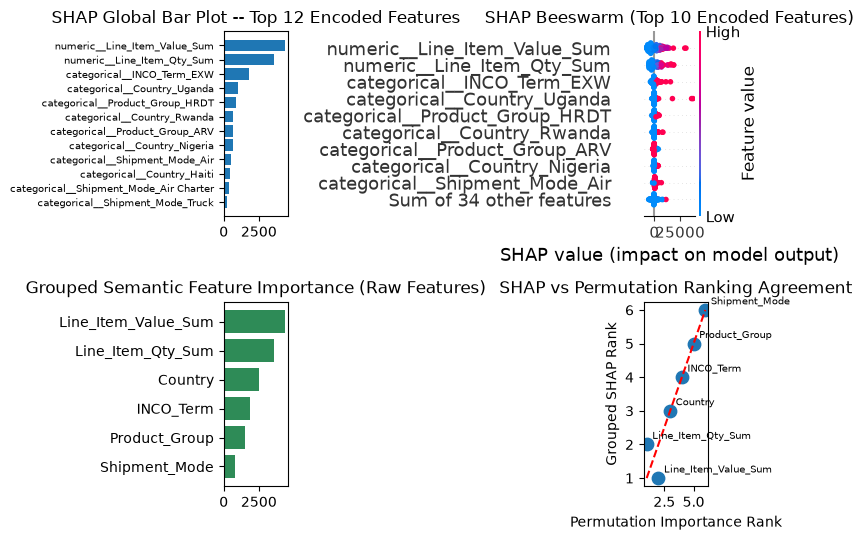

Analysis Question: SHAP ve Permutation Importance ayni feature'lari onemli buluyor mu?
Statistical Observation: Spearman rank correlation = 0.943 (n=6 raw features).
Engineering Interpretation: Yuksek korelasyon, iki farkli (model-agnostic vs model-specific attribution) yontemin tutarli bir sinyal buldugunu gosterir.
Decision Impact: Tutarli ranking, Section 13'teki stability/reliability degerlendirmesini guclendirir.
Limitations: n=6 raw feature ile Spearman korelasyonu kucuk orneklem etkisine aciktir; ranking disagreement mutlaka hesaplama hatasi anlamina gelmez.


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

top_shap = global_shap_importance.head(12).sort_values("Mean_Abs_SHAP")
axes[0, 0].barh(top_shap["Encoded_Feature"], top_shap["Mean_Abs_SHAP"])
axes[0, 0].set_title("SHAP Global Bar Plot -- Top 12 Encoded Features")
axes[0, 0].tick_params(axis="y", labelsize=7)

shap_explanation_obj = shap.Explanation(values=shap_values_primary, base_values=np.full(len(shap_values_primary), shap_base_value_primary),
                                          data=X_dev_explain_encoded, feature_names=list(encoded_feature_names))
plt.sca(axes[0, 1])
shap.plots.beeswarm(shap_explanation_obj, max_display=10, show=False)
axes[0, 1].set_title("SHAP Beeswarm (Top 10 Encoded Features)")

grp_sorted = grouped_shap_importance.sort_values("Mean_Abs_Grouped_SHAP")
axes[1, 0].barh(grp_sorted["Raw_Feature"], grp_sorted["Mean_Abs_Grouped_SHAP"], color="seagreen")
axes[1, 0].set_title("Grouped Semantic Feature Importance (Raw Features)")

perm_rank = permutation_importance_df.set_index("Raw_Feature")["Importance_Mean"].rank(ascending=False)
shap_rank = grouped_shap_importance.set_index("Raw_Feature")["Mean_Abs_Grouped_SHAP"].rank(ascending=False)
rank_compare = pd.DataFrame({"Permutation_Rank": perm_rank, "Grouped_SHAP_Rank": shap_rank}).loc[ALL_FEATS]
axes[1, 1].scatter(rank_compare["Permutation_Rank"], rank_compare["Grouped_SHAP_Rank"], s=80)
for feat, row in rank_compare.iterrows():
    axes[1, 1].annotate(feat, (row["Permutation_Rank"], row["Grouped_SHAP_Rank"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
axes[1, 1].plot([1, len(ALL_FEATS)], [1, len(ALL_FEATS)], color="red", linestyle="--")
axes[1, 1].set_xlabel("Permutation Importance Rank"); axes[1, 1].set_ylabel("Grouped SHAP Rank")
axes[1, 1].set_title("SHAP vs Permutation Ranking Agreement")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig03_global_shap_visualizations.png", dpi=100)
plt.show()

spearman_corr = rank_compare["Permutation_Rank"].corr(rank_compare["Grouped_SHAP_Rank"], method="spearman")
print(f"Analysis Question: SHAP ve Permutation Importance ayni feature'lari onemli buluyor mu?")
print(f"Statistical Observation: Spearman rank correlation = {spearman_corr:.3f} (n={len(ALL_FEATS)} raw features).")
print("Engineering Interpretation: Yuksek korelasyon, iki farkli (model-agnostic vs model-specific attribution) yontemin tutarli bir sinyal buldugunu gosterir.")
print("Decision Impact: Tutarli ranking, Section 13'teki stability/reliability degerlendirmesini guclendirir.")
print("Limitations: n=6 raw feature ile Spearman korelasyonu kucuk orneklem etkisine aciktir; ranking disagreement mutlaka hesaplama hatasi anlamina gelmez.")

## Section 12 — Local Explainability & Error Case Studies

**Ana Soru:** Model belirli bir shipment icin neden beklenenden yuksek veya
dusuk freight cost tahmin etti?

**Case Selection Policy (deterministic, onceden tanimli):**

- **Case A — Typical Prediction:** Development icinde median predicted magnitude.
- **Case B — High Predicted Cost:** En yuksek predicted freight cost (explanation sample icinde).
- **Case C — Low Predicted Cost:** En dusuk predicted freight cost.
- **Case D — High Absolute Error:** Stage 11'in 2014 residual artifact'indan secilmis, descriptive diagnostic case.
- **Case E — Model Disagreement:** ExtraTrees ile XGBoost'un en cok ayrildigi 2014 shipment'i.

**Kritik Kural:** Case D/E 2014 verisinden secilir ama **sadece aciklama/risk
analizi icindir** -- bu orneklerden yola cikarak yeni model tuning, feature
selection veya calibration YAPILMAMAKTADIR.

In [20]:
fitted_xgboost = alternative_pipeline.named_steps["model"]
shap_explainer_alt = shap.TreeExplainer(fitted_xgboost, model_output="raw")
shap_values_alt = shap_explainer_alt.shap_values(X_dev_explain_encoded)
shap_base_value_alt = np.asarray(shap_explainer_alt.expected_value).reshape(-1)[0]

predictions_explain_alt = fitted_xgboost.predict(X_dev_explain_encoded)
additivity_diff_alt = np.abs(predictions_explain_alt - (shap_base_value_alt + shap_values_alt.sum(axis=1)))
print(f"Secondary SHAP (M05-T000, XGBoost) additivity check: max diff = {additivity_diff_alt.max():.6f} USD")
assert additivity_diff_alt.max() < 1.0
print("Secondary model SHAP additivity PASSED.")

Secondary SHAP (M05-T000, XGBoost) additivity check: max diff = 0.070312 USD
Secondary model SHAP additivity PASSED.


In [21]:
preds_for_cases = fitted_extratrees.predict(X_dev_explain_encoded)
case_a_idx = int(np.argsort(np.abs(preds_for_cases - np.median(preds_for_cases)))[0])
case_b_idx = int(np.argmax(preds_for_cases))
case_c_idx = int(np.argmin(preds_for_cases))

val_eligible_keys_list = val_eligible_s12[PRIMARY_KEY].tolist()
primary_val_preds_s12 = primary_pipeline.predict(X_val_s12)
y_val_s12 = val_eligible_s12["Freight_Cost_USD"].astype(float).values
val_abs_err = np.abs(y_val_s12 - primary_val_preds_s12)
case_d_pos = int(np.argmax(val_abs_err))
case_d_key = val_eligible_keys_list[case_d_pos]

alt_val_preds_s12 = alternative_pipeline.predict(X_val_s12)
disagreement = np.abs(primary_val_preds_s12 - alt_val_preds_s12)
case_e_pos = int(np.argmax(disagreement))
case_e_key = val_eligible_keys_list[case_e_pos]

print("Case Selection (deterministic):")
print(f"  Case A (Typical, dev explanation sample idx={case_a_idx}): predicted={preds_for_cases[case_a_idx]:.2f} USD")
print(f"  Case B (High Predicted, idx={case_b_idx}): predicted={preds_for_cases[case_b_idx]:.2f} USD")
print(f"  Case C (Low Predicted, idx={case_c_idx}): predicted={preds_for_cases[case_c_idx]:.2f} USD")
print(f"  Case D (High Abs Error, 2014, key={case_d_key}): actual={y_val_s12[case_d_pos]:.2f}, predicted={primary_val_preds_s12[case_d_pos]:.2f}, abs_err={val_abs_err[case_d_pos]:.2f} USD")
print(f"  Case E (Model Disagreement, 2014, key={case_e_key}): ExtraTrees={primary_val_preds_s12[case_e_pos]:.2f}, XGBoost={alt_val_preds_s12[case_e_pos]:.2f}, diff={disagreement[case_e_pos]:.2f} USD")

Case Selection (deterministic):
  Case A (Typical, dev explanation sample idx=104): predicted=7745.63 USD
  Case B (High Predicted, idx=114): predicted=96820.07 USD
  Case C (Low Predicted, idx=151): predicted=1449.82 USD
  Case D (High Abs Error, 2014, key=DN-3732): actual=9857.35, predicted=88109.69, abs_err=78252.34 USD
  Case E (Model Disagreement, 2014, key=ASN-23441): ExtraTrees=73232.78, XGBoost=95654.76, diff=22421.97 USD


In [22]:
X_case_d = val_eligible_s12.iloc[[case_d_pos]][ALL_FEATS]
X_case_e = val_eligible_s12.iloc[[case_e_pos]][ALL_FEATS]
X_case_d_encoded = fitted_preprocessor.transform(X_case_d)
X_case_e_encoded = fitted_preprocessor.transform(X_case_e)

shap_case_d_primary = shap_explainer_primary.shap_values(X_case_d_encoded)
shap_case_e_primary = shap_explainer_primary.shap_values(X_case_e_encoded)
shap_case_e_alt = shap_explainer_alt.shap_values(X_case_e_encoded)

local_cases_rows = []
case_defs = [("A_Typical", case_a_idx, "dev"), ("B_High_Predicted", case_b_idx, "dev"), ("C_Low_Predicted", case_c_idx, "dev")]
for case_name, idx, _ in case_defs:
    local_cases_rows.append({"Case": case_name, "Predicted_USD": float(preds_for_cases[idx]), "Baseline_USD": float(shap_base_value_primary),
                              "Top_Feature": encoded_feature_names[np.argmax(np.abs(shap_values_primary[idx]))],
                              "Top_Feature_SHAP": float(shap_values_primary[idx][np.argmax(np.abs(shap_values_primary[idx]))])})
local_cases_rows.append({"Case": "D_High_Abs_Error_2014", "Predicted_USD": float(primary_val_preds_s12[case_d_pos]), "Baseline_USD": float(shap_base_value_primary),
                          "Top_Feature": encoded_feature_names[np.argmax(np.abs(shap_case_d_primary[0]))], "Top_Feature_SHAP": float(shap_case_d_primary[0][np.argmax(np.abs(shap_case_d_primary[0]))]),
                          "Actual_USD": float(y_val_s12[case_d_pos]), "Abs_Error_USD": float(val_abs_err[case_d_pos])})
local_cases_rows.append({"Case": "E_Model_Disagreement_2014", "Predicted_USD": float(primary_val_preds_s12[case_e_pos]), "Baseline_USD": float(shap_base_value_primary),
                          "Top_Feature": encoded_feature_names[np.argmax(np.abs(shap_case_e_primary[0]))], "Top_Feature_SHAP": float(shap_case_e_primary[0][np.argmax(np.abs(shap_case_e_primary[0]))]),
                          "Alternative_Predicted_USD": float(alt_val_preds_s12[case_e_pos]), "Disagreement_USD": float(disagreement[case_e_pos])})
local_explanations = pd.DataFrame(local_cases_rows)
local_explanations.to_csv(ARTIFACT_DIR / "stage12_local_explanations.csv", index=False)
print("Wrote stage12_local_explanations.csv")
local_explanations

Wrote stage12_local_explanations.csv


,Case,Predicted_USD,Baseline_USD,Top_Feature,Top_Feature_SHAP,Actual_USD,Abs_Error_USD,Alternative_Predicted_USD,Disagreement_USD
0,A_Typical,7745.626088,10456.218412,categorical__Country_Nigeria,2990.936001,NaN,NaN,NaN,NaN
1,B_High_Predicted,96820.070278,10456.218412,categorical__Country_Uganda,37538.124132,NaN,NaN,NaN,NaN
2,C_Low_Predicted,1449.822664,10456.218412,numeric__Line_Item_Value_Sum,-5339.201357,NaN,NaN,NaN,NaN
3,D_High_Abs_Error_2014,88109.693863,10456.218412,categorical__Country_Uganda,34006.529827,9857.35,78252.343863,NaN,NaN
4,E_Model_Disagreement_2014,73232.783149,10456.218412,numeric__Line_Item_Value_Sum,21295.853536,NaN,NaN,95654.757812,22421.974664


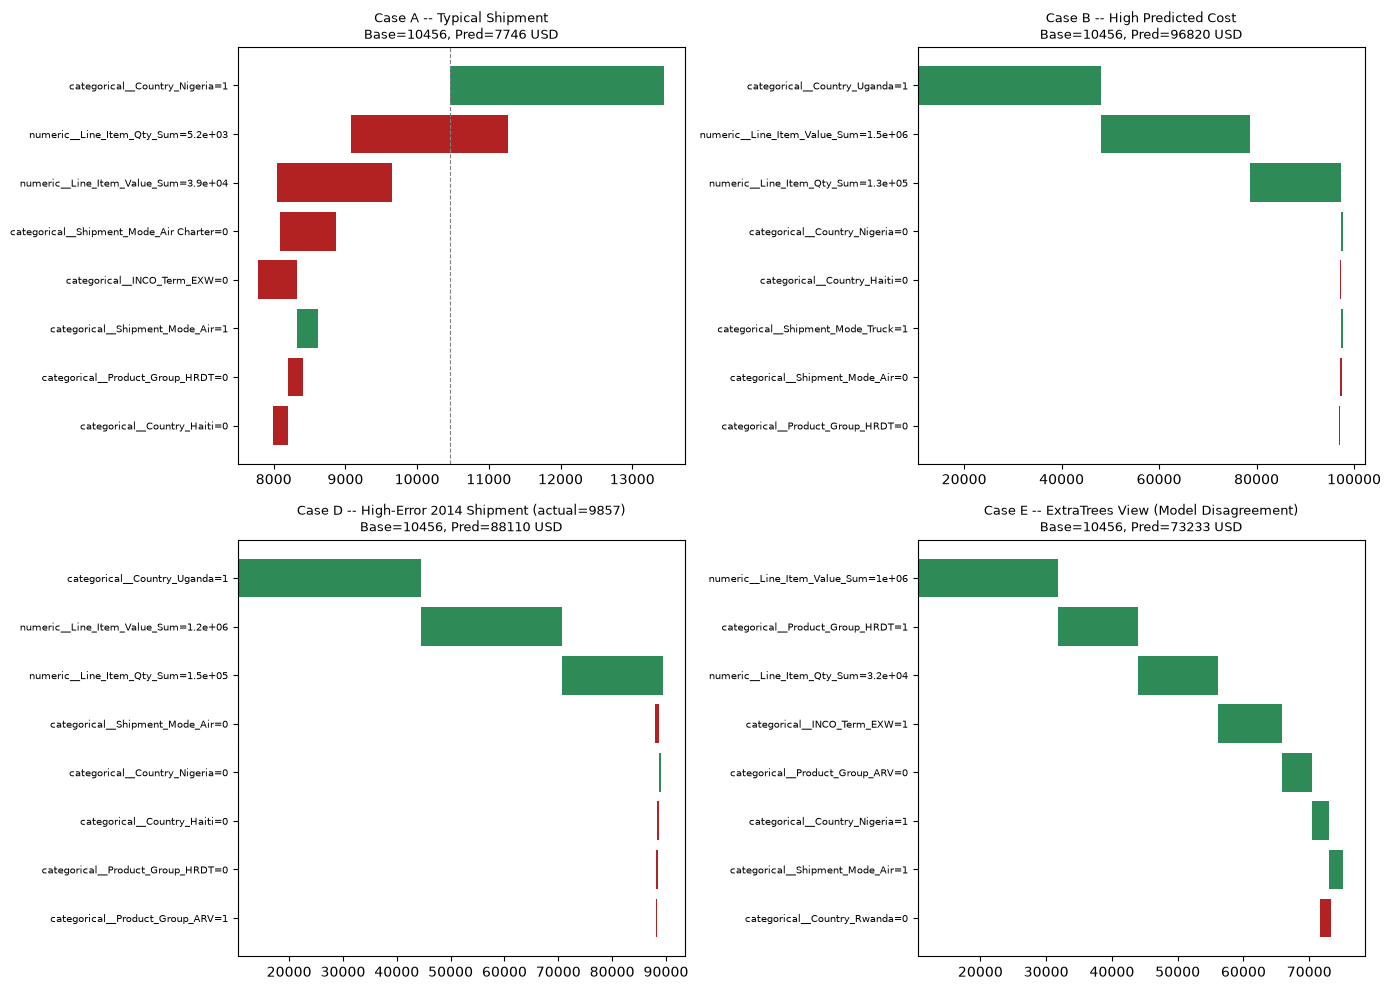

Analysis Question: Model, bu dort farkli shipment icin tahminini hangi feature'lara dayandiriyor?
Statistical Observation: Waterfall grafikleri yukarida -- her biri base_value'dan predicted degere giden feature katkilarini gosterir.
Engineering Interpretation: 'Bu feature degistirilirse maliyet SHAP degeri kadar degisir' ifadesi YANLIS yorumdur -- SHAP model attribution'dir, nedensel kanit degildir.
Decision Impact: Section 13'teki correlated-feature ve model-disagreement analizine girdi saglar.
Limitations: Case D/E 2014'ten secildi -- bu SADECE aciklama/risk amaclidir, yeni model tuning icin kullanilmamistir.


In [23]:
def plot_waterfall(ax, base_value, shap_vals, feature_names, feature_vals, prediction, title, top_n=8):
    order = np.argsort(np.abs(shap_vals))[::-1][:top_n]
    labels = [f"{feature_names[i]}={feature_vals[i]:.2g}" if isinstance(feature_vals[i], (int, float, np.floating)) else f"{feature_names[i]}" for i in order]
    vals = shap_vals[order]
    cum = base_value
    for i, v in enumerate(vals):
        color = "firebrick" if v < 0 else "seagreen"
        ax.barh(i, v, left=cum if v > 0 else cum + v, color=color)
        cum += v
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
    ax.axvline(base_value, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(f"{title}\nBase={base_value:.0f}, Pred={prediction:.0f} USD", fontsize=9)
    ax.invert_yaxis()


fig, axes = plt.subplots(2, 2, figsize=(14, 10))
feat_vals_dev = X_dev_explain_encoded[case_a_idx]
plot_waterfall(axes[0, 0], shap_base_value_primary, shap_values_primary[case_a_idx], list(encoded_feature_names), feat_vals_dev, preds_for_cases[case_a_idx], "Case A -- Typical Shipment")

feat_vals_b = X_dev_explain_encoded[case_b_idx]
plot_waterfall(axes[0, 1], shap_base_value_primary, shap_values_primary[case_b_idx], list(encoded_feature_names), feat_vals_b, preds_for_cases[case_b_idx], "Case B -- High Predicted Cost")

feat_vals_d = X_case_d_encoded[0]
plot_waterfall(axes[1, 0], shap_base_value_primary, shap_case_d_primary[0], list(encoded_feature_names), feat_vals_d, primary_val_preds_s12[case_d_pos], f"Case D -- High-Error 2014 Shipment (actual={y_val_s12[case_d_pos]:.0f})")

feat_vals_e = X_case_e_encoded[0]
plot_waterfall(axes[1, 1], shap_base_value_primary, shap_case_e_primary[0], list(encoded_feature_names), feat_vals_e, primary_val_preds_s12[case_e_pos], "Case E -- ExtraTrees View (Model Disagreement)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig04_local_waterfalls.png", dpi=100)
plt.show()
print("Analysis Question: Model, bu dort farkli shipment icin tahminini hangi feature'lara dayandiriyor?")
print("Statistical Observation: Waterfall grafikleri yukarida -- her biri base_value'dan predicted degere giden feature katkilarini gosterir.")
print("Engineering Interpretation: 'Bu feature degistirilirse maliyet SHAP degeri kadar degisir' ifadesi YANLIS yorumdur -- SHAP model attribution'dir, nedensel kanit degildir.")
print("Decision Impact: Section 13'teki correlated-feature ve model-disagreement analizine girdi saglar.")
print("Limitations: Case D/E 2014'ten secildi -- bu SADECE aciklama/risk amaclidir, yeni model tuning icin kullanilmamistir.")

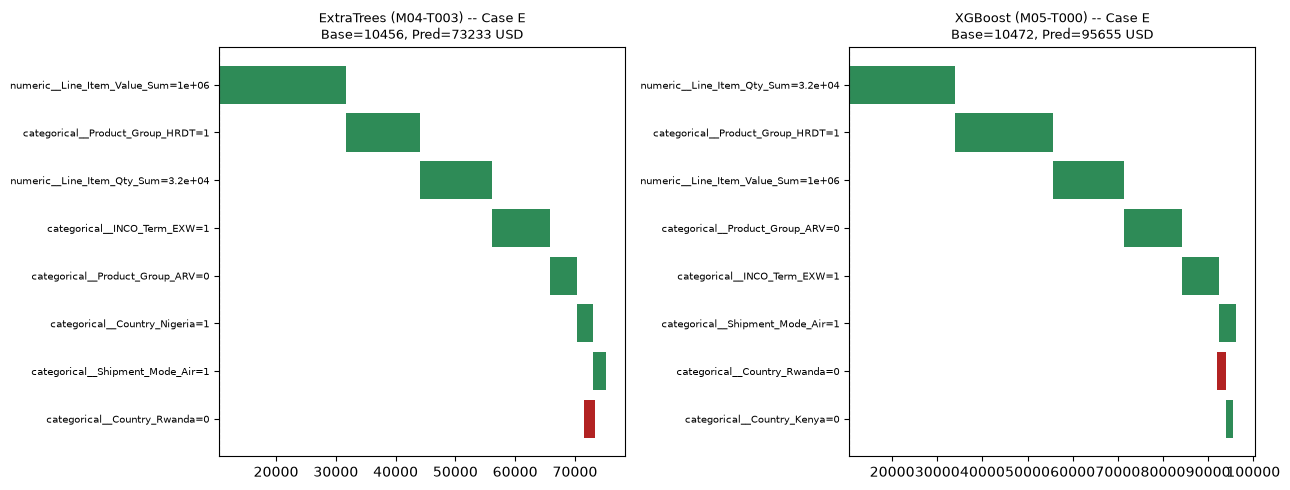

Analysis Question: Iki model, ayni shipment icin NEDEN farkli tahmin uretiyor (73233 vs 95655 USD)?
Statistical Observation: Her iki modelin top feature contribution'lari yukaridaki waterfall'larda karsilastirilmistir.
Engineering Interpretation: Farkli model mimarileri (bagging vs boosting), ayni feature'a farkli agirlik/nonlinear etki atfedebilir -- bu bir hata degil, model-specific explanation farklidir.
Decision Impact: Stage 13 risk flag'lerinde 'model disagreement' bir izleme sinyali olarak dokumante edilecektir.
Limitations: Bu TEK bir shipment'in analizidir -- genel bir model karsilastirmasi degildir (bkz Stage 11 Section 06 icin agregat analiz).


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_waterfall(axes[0], shap_base_value_primary, shap_case_e_primary[0], list(encoded_feature_names), feat_vals_e, primary_val_preds_s12[case_e_pos], "ExtraTrees (M04-T003) -- Case E")
plot_waterfall(axes[1], shap_base_value_alt, shap_case_e_alt[0], list(encoded_feature_names), feat_vals_e, alt_val_preds_s12[case_e_pos], "XGBoost (M05-T000) -- Case E")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig05_model_disagreement_explanation.png", dpi=100)
plt.show()
print(f"Analysis Question: Iki model, ayni shipment icin NEDEN farkli tahmin uretiyor ({primary_val_preds_s12[case_e_pos]:.0f} vs {alt_val_preds_s12[case_e_pos]:.0f} USD)?")
print("Statistical Observation: Her iki modelin top feature contribution'lari yukaridaki waterfall'larda karsilastirilmistir.")
print("Engineering Interpretation: Farkli model mimarileri (bagging vs boosting), ayni feature'a farkli agirlik/nonlinear etki atfedebilir -- bu bir hata degil, model-specific explanation farklidir.")
print("Decision Impact: Stage 13 risk flag'lerinde 'model disagreement' bir izleme sinyali olarak dokumante edilecektir.")
print("Limitations: Bu TEK bir shipment'in analizidir -- genel bir model karsilastirmasi degildir (bkz Stage 11 Section 06 icin agregat analiz).")

## Section 13 — Explainability Reliability & Feature Dependence

**Learning Objective:** SHAP degerlerini, bilimsel sinirlamalariyla birlikte
dogru yorumlamak.

### Part A — Correlated Features (Stage 07 Hatirlatma)

Stage 07'de gozlenen bulgu: Value-related features permutation importance
acisindan onemli gorunurken, feature-group ablation sonuclarinda modelin bazi
durumlarda Value grubu CIKARILDIGINDA daha iyi performans gosterdigi
gozlenmistir. Bu, **Correlated Information / Feature Redundancy** ile
iliskilidir -- feature cikarildiginda model, redundant bilgiyi diger
feature'lara (orn. Qty) yeniden dagitabilir (**Attribution Redistribution**).
Bu notebook'ta model yeniden egitilmemektedir; bu sadece gecmis bulgunun
SHAP/Permutation merceginden yeniden degerlendirilmesidir.

### Part B — SHAP Feature Perturbation Yaklasimlari (Teorik)

`shap.TreeExplainer`, iki farkli background assumption sunar:

- **`tree_path_dependent`**: Egitim verisindeki path frequency'lerini kullanir,
  ayri bir background dataset gerektirmez (bu notebook'ta kullanilan varsayilan).
- **`interventional`**: Acik bir background dataset gerektirir, feature'lar
  arasindaki correlation'i kirarak (marginal) Shapley degerlerini hesaplar.

Bu iki yaklasim **farkli varsayimlar** kullanir -- biri feature correlation
yapisini korur (tree_path_dependent), digeri feature'lari bagimsiz varsayar
(interventional). Hicbiri "digerinden kesin dogru" degildir; hangisinin uygun
oldugu use-case'e baglidir.

In [25]:
shap_explainer_interventional = shap.TreeExplainer(fitted_extratrees, data=X_dev_explain_encoded, feature_perturbation="interventional", model_output="raw")
t0 = time.perf_counter()
shap_values_interventional = shap_explainer_interventional.shap_values(X_dev_explain_encoded[:50])
interventional_time = time.perf_counter() - t0
print(f"Interventional SHAP computed for 50 observations in {interventional_time:.2f}s (bounded, deterministic background = same 200-row explanation sample)")

grouped_shap_interventional = pd.DataFrame({raw_feat: pd.DataFrame(shap_values_interventional, columns=encoded_feature_names)[[c for c in encoded_feature_names if raw_source_map[c] == raw_feat]].sum(axis=1) for raw_feat in ALL_FEATS}).abs().mean(axis=0)
grouped_shap_pathdep_same50 = grouped_shap_signed.iloc[:50].abs().mean(axis=0)
background_sensitivity = pd.DataFrame({"Raw_Feature": ALL_FEATS, "TreePathDependent_MeanAbsSHAP": grouped_shap_pathdep_same50.loc[ALL_FEATS].values, "Interventional_MeanAbsSHAP": grouped_shap_interventional.loc[ALL_FEATS].values})
background_sensitivity["Abs_Diff"] = (background_sensitivity["TreePathDependent_MeanAbsSHAP"] - background_sensitivity["Interventional_MeanAbsSHAP"]).abs()
print("\nBackground/perturbation sensitivity (same 50 observations, two feature_perturbation modes):")
print(background_sensitivity)

Interventional SHAP computed for 50 observations in 1.01s (bounded, deterministic background = same 200-row explanation sample)

Background/perturbation sensitivity (same 50 observations, two feature_perturbation modes):
           Raw_Feature  TreePathDependent_MeanAbsSHAP  \
0    Line_Item_Qty_Sum                    2907.083882   
1  Line_Item_Value_Sum                    3808.639625   
2        Shipment_Mode                     750.537532   
3            INCO_Term                    1574.265689   
4              Country                    2063.079644   
5        Product_Group                    1490.981859   

   Interventional_MeanAbsSHAP     Abs_Diff  
0                 4138.153997  1231.070115  
1                 3420.047964   388.591660  
2                  834.179832    83.642300  
3                 2064.064193   489.798504  
4                 1761.797331   301.282313  
5                 2256.159237   765.177378  


### Part C — Explanation Stability (Farkli Deterministic Background Samples)

Farkli (deterministic, farkli seed) development background sample'lari
uzerinde grouped SHAP importance ranking'inin ne kadar stabil oldugunu
degerlendiriyoruz. **Stage 10 optimization calismalari burada tekrarlanmiyor
-- sadece explanation sample degisiyor, model/hyperparameters sabit.**

In [26]:
stability_seeds = [42, 7, 123]
stability_rows = []
grouped_rankings = {}
for seed in stability_seeds:
    rng_s = np.random.default_rng(seed)
    idx_s = rng_s.choice(len(X_dev), size=MAX_EXPLANATION_SAMPLES, replace=False)
    X_s_encoded = fitted_preprocessor.transform(X_dev.iloc[idx_s])
    shap_vals_s = shap_explainer_primary.shap_values(X_s_encoded)
    shap_df_s = pd.DataFrame(shap_vals_s, columns=encoded_feature_names)
    grouped_s = pd.Series({raw_feat: shap_df_s[[c for c in encoded_feature_names if raw_source_map[c] == raw_feat]].sum(axis=1).abs().mean() for raw_feat in ALL_FEATS})
    grouped_rankings[seed] = grouped_s.rank(ascending=False)
    for feat in ALL_FEATS:
        stability_rows.append({"Seed": seed, "Raw_Feature": feat, "Mean_Abs_Grouped_SHAP": grouped_s[feat]})

explanation_stability = pd.DataFrame(stability_rows)
explanation_stability.to_csv(ARTIFACT_DIR / "stage12_explanation_stability.csv", index=False)
rank_matrix = pd.DataFrame(grouped_rankings)
rank_range = (rank_matrix.max(axis=1) - rank_matrix.min(axis=1))
print("Rank range (max-min) across 3 deterministic background samples, per raw feature (0 = perfectly stable):")
print(rank_range.sort_values(ascending=False))
print("\nWrote stage12_explanation_stability.csv")

explanation_disagreement = pd.DataFrame({"Raw_Feature": ALL_FEATS, "Permutation_Rank": perm_rank.loc[ALL_FEATS].values, "Grouped_SHAP_Rank": shap_rank.loc[ALL_FEATS].values, "Rank_Disagreement": (perm_rank.loc[ALL_FEATS] - shap_rank.loc[ALL_FEATS]).abs().values})
explanation_disagreement.to_csv(ARTIFACT_DIR / "stage12_explanation_disagreement.csv", index=False)
print("Wrote stage12_explanation_disagreement.csv")

Rank range (max-min) across 3 deterministic background samples, per raw feature (0 = perfectly stable):
Line_Item_Qty_Sum      0.0
Line_Item_Value_Sum    0.0
Shipment_Mode          0.0
INCO_Term              0.0
Country                0.0
Product_Group          0.0
dtype: float64

Wrote stage12_explanation_stability.csv
Wrote stage12_explanation_disagreement.csv


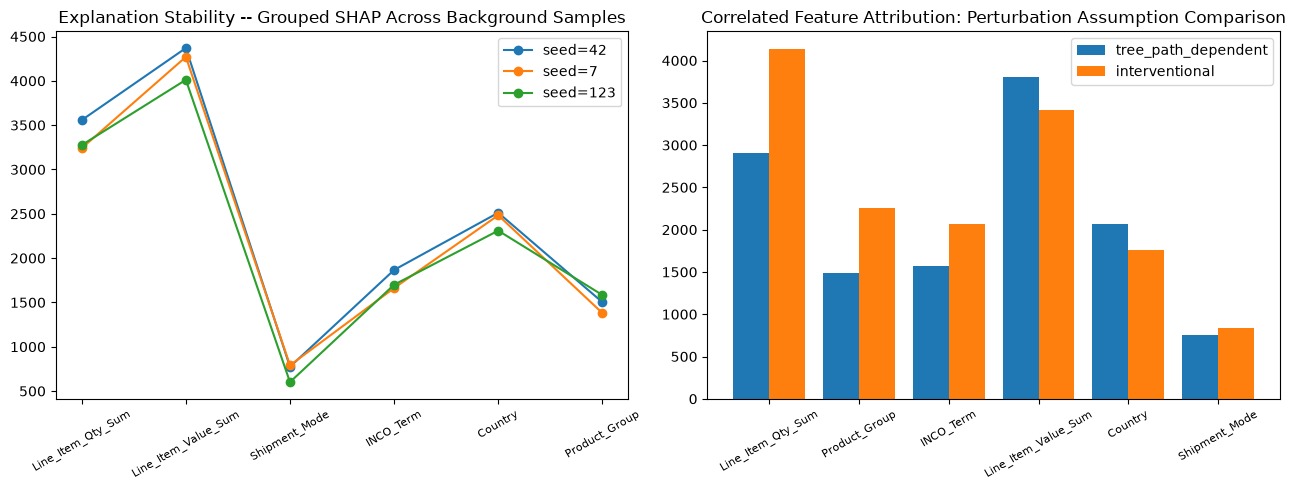

Analysis Question: SHAP attribution'lari farkli background sample'lar ve perturbation assumption'lar altinda ne kadar stabil?
Statistical Observation: En buyuk rank range=0 (feature: Line_Item_Qty_Sum); en buyuk tree_path_dependent-vs-interventional farki feature: Line_Item_Qty_Sum (1231.07 USD).
Engineering Interpretation: Ranking disagreement mutlaka hesaplama hatasi degildir -- farkli yontemler farkli sorulari cevaplar (marginal vs conditional contribution).
Decision Impact: Stage 13 risk register'ina 'explanation background sensitivity' bir risk olarak eklenecektir.
Limitations: Bu analiz, Stage 10'un hyperparameter optimization calismalarini TEKRARLAMAMAKTADIR -- sadece sabit model uzerinde SHAP background degisimi test edilmistir.


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for seed in stability_seeds:
    sub = explanation_stability[explanation_stability["Seed"] == seed].set_index("Raw_Feature").loc[ALL_FEATS]
    axes[0].plot(ALL_FEATS, sub["Mean_Abs_Grouped_SHAP"], marker="o", label=f"seed={seed}")
axes[0].set_title("Explanation Stability -- Grouped SHAP Across Background Samples")
axes[0].tick_params(axis="x", rotation=30, labelsize=8)
axes[0].legend()

bs_sorted = background_sensitivity.sort_values("Abs_Diff", ascending=False)
x = np.arange(len(bs_sorted))
axes[1].bar(x - 0.2, bs_sorted["TreePathDependent_MeanAbsSHAP"], width=0.4, label="tree_path_dependent")
axes[1].bar(x + 0.2, bs_sorted["Interventional_MeanAbsSHAP"], width=0.4, label="interventional")
axes[1].set_xticks(x); axes[1].set_xticklabels(bs_sorted["Raw_Feature"], rotation=30, fontsize=8)
axes[1].set_title("Correlated Feature Attribution: Perturbation Assumption Comparison")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig06_explainability_reliability.png", dpi=100)
plt.show()
print("Analysis Question: SHAP attribution'lari farkli background sample'lar ve perturbation assumption'lar altinda ne kadar stabil?")
print(f"Statistical Observation: En buyuk rank range={int(rank_range.max())} (feature: {rank_range.idxmax()}); en buyuk tree_path_dependent-vs-interventional farki feature: {bs_sorted.iloc[0]['Raw_Feature']} ({bs_sorted.iloc[0]['Abs_Diff']:.2f} USD).")
print("Engineering Interpretation: Ranking disagreement mutlaka hesaplama hatasi degildir -- farkli yontemler farkli sorulari cevaplar (marginal vs conditional contribution).")
print("Decision Impact: Stage 13 risk register'ina 'explanation background sensitivity' bir risk olarak eklenecektir.")
print("Limitations: Bu analiz, Stage 10'un hyperparameter optimization calismalarini TEKRARLAMAMAKTADIR -- sadece sabit model uzerinde SHAP background degisimi test edilmistir.")

## Section 14 — Prediction Uncertainty & Conformal Methods

**Ana Soru:** Bir freight cost tahmini icin belirsizligi nasil ifade edebiliriz
ve prediction interval'in beklenen coverage seviyesine ulasmasini nasil
olceriz?

### Part A — Uncertainty Fundamentals

| Kavram | Aciklama |
|---|---|
| **Aleatoric Uncertainty** | Verinin dogal variability/noise kaynakli belirsizligi -- ayni feature degerlerine sahip iki shipment yine de farkli gercek maliyete sahip olabilir. Daha fazla veri ile AZALMAZ. |
| **Epistemic Uncertainty** | Model bilgisi, veri miktari veya model specification eksikliginden kaynaklanan belirsizlik. Daha fazla/daha iyi veri ile AZALABILIR. |
| **Prediction Interval** | YENI bir observation'in gercek target degerini kapsamasi AMAÇLANAN aralik. |
| **Confidence Interval** | Bir population parametresi (orn. ortalama) HAKKINDAKI belirsizligi ifade eden aralik. |

**Kritik Ayrim:** Prediction Interval ve Confidence Interval **AYNI KAVRAM
DEGILDIR**. Bu notebook prediction interval ile ilgilenir -- tek bir shipment'in
gercek freight cost'unu kapsama hedefiyle.

### Part B — Conformal Prediction (Temel Adimlar)

1. Train model (frozen, Object A veya research replica).
2. Independent calibration predictions al.
3. Conformity scores hesapla: $r_i = |y_i - \hat y_i|$.
4. Calibration quantile tahmin et.
5. Prediction interval olustur: $L(x) = \hat y(x) - q_\alpha$, $U(x) = \hat y(x) + q_\alpha$.
6. Future coverage'i degerlendir.

### Conformal Quantile (Finite-Sample Conservative)

Nominal coverage $1-\alpha$ icin:

$$k = \left\lceil (n_{cal}+1)(1-\alpha) \right\rceil$$

Sorted calibration residuals uzerinden $k$-inci order statistic secilir. **Eger
gerekli quantile index calibration sample size nedeniyle mevcut degilse,
SESSIZCE yanlis bir quantile kullanilmaz -- method requirements kontrol edilir,
gerekirse unsupported/unbounded status raporlanir.**

### Kritik Teorik Sinirlama

Standard split conformal finite-sample marginal coverage guarantee,
calibration ve test observations arasinda **exchangeability** varsayimina
dayanir. Freight shipments **temporal olarak** distribution shift, nonstationarity,
selection bias ve degisen segment composition gosterebilir.

**Bu nedenle: nominal %90 interval, future shipments icin otomatik guaranteed
%90 coverage anlamina GELMEZ.**

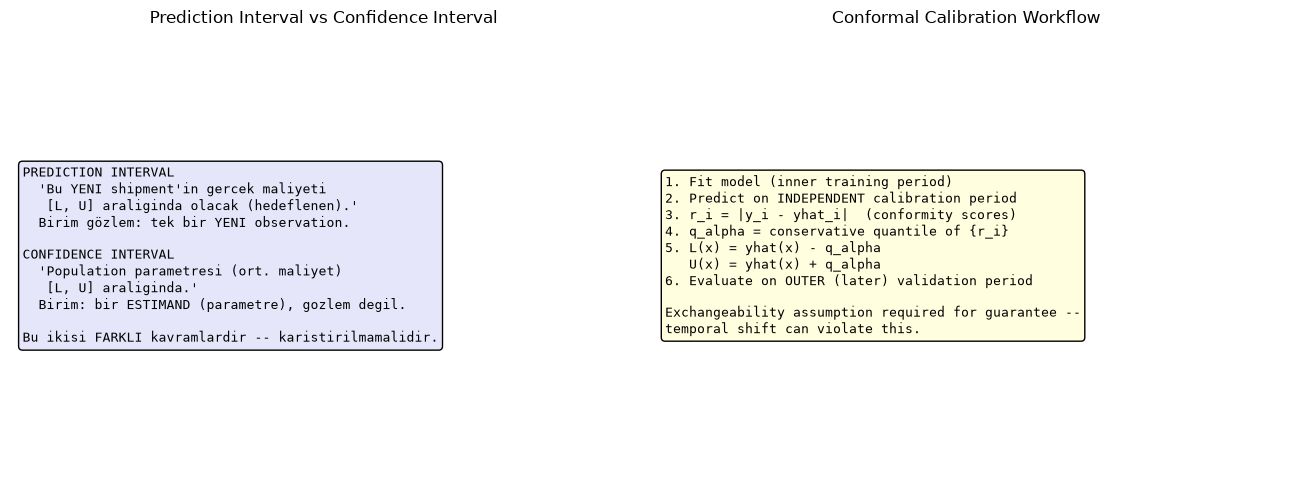

Analysis Question: Prediction interval ile confidence interval neden farkli kavramlardir?
Statistical Observation: Diyagramlar yukarida.
Engineering Interpretation: Conformal prediction, bir YENI observation icin interval uretir -- bir parametre tahmini degildir.
Decision Impact: Section 15-18'deki calibration tasarimi bu ayrima dayanacaktir.
Limitations: Bu kavramsal bir diyagramdir, olcum degildir.


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.axis("off")
pi_vs_ci_text = (
    "PREDICTION INTERVAL\n"
    "  'Bu YENI shipment'in gercek maliyeti\n"
    "   [L, U] araliginda olacak (hedeflenen).'\n"
    "  Birim gözlem: tek bir YENI observation.\n\n"
    "CONFIDENCE INTERVAL\n"
    "  'Population parametresi (ort. maliyet)\n"
    "   [L, U] araliginda.'\n"
    "  Birim: bir ESTIMAND (parametre), gozlem degil.\n\n"
    "Bu ikisi FARKLI kavramlardir -- karistirilmamalidir."
)
ax.text(0.02, 0.5, pi_vs_ci_text, fontsize=9.5, va="center", family="monospace", bbox=dict(boxstyle="round", fc="lavender"))
ax.set_title("Prediction Interval vs Confidence Interval")

ax = axes[1]
ax.axis("off")
workflow_text = (
    "1. Fit model (inner training period)\n"
    "2. Predict on INDEPENDENT calibration period\n"
    "3. r_i = |y_i - yhat_i|  (conformity scores)\n"
    "4. q_alpha = conservative quantile of {r_i}\n"
    "5. L(x) = yhat(x) - q_alpha\n"
    "   U(x) = yhat(x) + q_alpha\n"
    "6. Evaluate on OUTER (later) validation period\n\n"
    "Exchangeability assumption required for guarantee --\n"
    "temporal shift can violate this."
)
ax.text(0.02, 0.5, workflow_text, fontsize=9, va="center", family="monospace", bbox=dict(boxstyle="round", fc="lightyellow"))
ax.set_title("Conformal Calibration Workflow")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig07_conformal_theory.png", dpi=100)
plt.show()
print("Analysis Question: Prediction interval ile confidence interval neden farkli kavramlardir?")
print("Statistical Observation: Diyagramlar yukarida.")
print("Engineering Interpretation: Conformal prediction, bir YENI observation icin interval uretir -- bir parametre tahmini degildir.")
print("Decision Impact: Section 15-18'deki calibration tasarimi bu ayrima dayanacaktir.")
print("Limitations: Bu kavramsal bir diyagramdir, olcum degildir.")

## Section 15 — Calibration Leakage Demonstration

**Yanlis Yaklasim (Egitim Amacli Gosterim):**

```text
Train model on 2006-2013
        |
        v
Predict 2013 training records
        |
        v
Use 2013 TRAINING residuals for calibration
        |
        v
Claim valid split conformal intervals  <-- YANLIS
```

Bu yaklasim **ordinary split conformal calibration DEGILDIR**. 2013
observations model training sirasinda kullanildigi icin, bu residuals
**bagimsiz degildir** -- model bu gozlemleri zaten "gormustur" ve onlara
asiri iyi uyum saglamis olabilir (overfitting), bu da residuals'i yapay
olarak KUCUK gosterir -> interval'lar yapay olarak DAR olur -> gercek coverage
nominal seviyenin ALTINDA kalir.

**Dogru Ilke:** Model fitting, calibration ve interval evaluation
observations **AYRIK TUTULMALIDIR**. Calibration target degerleri hicbir
zaman aynı fitted modelin training labels'i olarak kullanilmamalidir.

In [29]:
fold4_train_keys = fold_manifest.loc[(fold_manifest["Fold_ID"] == 4) & (fold_manifest["Role"] == "Train"), "Shipment_Key"]
fold4_train_sv = dev_eligible[dev_eligible[PRIMARY_KEY].isin(fold4_train_keys)]
leakage_demo_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", ExtraTreesRegressor(**PRIMARY_PARAMS, bootstrap=False, random_state=RANDOM_SEED, n_jobs=2))])
leakage_demo_pipeline.fit(fold4_train_sv[ALL_FEATS], fold4_train_sv["Freight_Cost_USD"].astype(float))

in_sample_preds = leakage_demo_pipeline.predict(fold4_train_sv[ALL_FEATS])
in_sample_residuals = np.abs(fold4_train_sv["Freight_Cost_USD"].astype(float).values - in_sample_preds)

fold3_cal_keys = fold_manifest.loc[(fold_manifest["Fold_ID"] == 3) & (fold_manifest["Role"] == "CV_Validation"), "Shipment_Key"]
honest_cal_sv = dev_eligible[dev_eligible[PRIMARY_KEY].isin(fold3_cal_keys)]
honest_cal_preds = leakage_demo_pipeline.predict(honest_cal_sv[ALL_FEATS])
honest_cal_residuals = np.abs(honest_cal_sv["Freight_Cost_USD"].astype(float).values - honest_cal_preds)

print(f"LEAKY calibration residuals (same model's OWN training data, n={len(in_sample_residuals)}): median={np.median(in_sample_residuals):.2f}, P90={np.quantile(in_sample_residuals, 0.90):.2f} USD")
print(f"HONEST calibration residuals (independent period the model never trained on, n={len(honest_cal_residuals)}): median={np.median(honest_cal_residuals):.2f}, P90={np.quantile(honest_cal_residuals, 0.90):.2f} USD")
print(f"\nLeaky P90 is {100*(1 - np.quantile(in_sample_residuals, 0.90)/np.quantile(honest_cal_residuals, 0.90)):.1f}% SMALLER than honest P90 -- demonstrating the artificially narrow intervals that leakage would produce.")
print("This leaky approach is NOT used anywhere else in this notebook -- demonstration only.")

LEAKY calibration residuals (same model's OWN training data, n=4152): median=1956.73, P90=7900.34 USD
HONEST calibration residuals (independent period the model never trained on, n=861): median=1924.58, P90=9511.30 USD

Leaky P90 is 16.9% SMALLER than honest P90 -- demonstrating the artificially narrow intervals that leakage would produce.
This leaky approach is NOT used anywhere else in this notebook -- demonstration only.


## Section 16 — Split Conformal Calibrator Implementation

**Primary Method:** Absolute Residual Split Conformal.

$$r_i = |y_i - \hat y_i| \qquad k = \lceil (n_{cal}+1)(1-\alpha) \rceil \qquad
L(x) = \hat y(x) - q_\alpha, \quad U(x) = \hat y(x) + q_\alpha$$

In [30]:
# Absolute-residual split conformal interval calibrator.
class SplitConformalCalibrator:
    def __init__(self, minimum_calibration_samples: int = 30, nonnegative_floor: bool = False):
        self.minimum_calibration_samples = minimum_calibration_samples
        self.nonnegative_floor = nonnegative_floor
        self._quantiles: dict[float, float] = {}
        self._n_calibration = 0
        self._fitted = False

    def fit(self, y_calibration: np.ndarray, calibration_predictions: np.ndarray) -> "SplitConformalCalibrator":
        y_calibration = np.asarray(y_calibration, dtype=float)
        calibration_predictions = np.asarray(calibration_predictions, dtype=float)
        if len(y_calibration) != len(calibration_predictions):
            raise ValueError("y_calibration and calibration_predictions must have the same length")
        if not (np.isfinite(y_calibration).all() and np.isfinite(calibration_predictions).all()):
            raise ValueError("y_calibration and calibration_predictions must be finite")
        if len(y_calibration) < self.minimum_calibration_samples:
            raise ValueError(f"insufficient calibration sample: {len(y_calibration)} < {self.minimum_calibration_samples}")
        self._residuals = np.abs(y_calibration - calibration_predictions)
        assert (self._residuals >= 0).all()
        self._n_calibration = len(self._residuals)
        self._fitted = True
        return self

    def _quantile_for_alpha(self, alpha: float) -> float:
        if not 0.0 < alpha < 1.0:
            raise ValueError(f"alpha must be in (0, 1), got {alpha}")
        if alpha in self._quantiles:
            return self._quantiles[alpha]
        n = self._n_calibration
        k = int(np.ceil((n + 1) * (1 - alpha)))
        k = min(k, n)
        sorted_residuals = np.sort(self._residuals)
        q = float(sorted_residuals[k - 1])
        self._quantiles[alpha] = q
        return q

    def predict_interval(self, predictions: np.ndarray, alpha: float) -> tuple[np.ndarray, np.ndarray]:
        if not self._fitted:
            raise RuntimeError("calibrator not fitted")
        predictions = np.asarray(predictions, dtype=float)
        if not np.isfinite(predictions).all():
            raise ValueError("predictions must be finite")
        q = self._quantile_for_alpha(alpha)
        lower = predictions - q
        upper = predictions + q
        if self.nonnegative_floor:
            lower = np.clip(lower, 0.0, None)
        assert (lower <= upper + 1e-9).all()
        return lower, upper


print("SplitConformalCalibrator defined.")

SplitConformalCalibrator defined.


In [31]:
def _assert_close(a, b, tol=1e-6, msg=""):
    assert abs(a - b) < tol, f"{msg}: {a} vs {b}"


# Unit Test 1 -- correct residual calculation
_cal = SplitConformalCalibrator(minimum_calibration_samples=3).fit(y_calibration=np.array([10.0, 20.0, 30.0]), calibration_predictions=np.array([8.0, 25.0, 28.0]))
_assert_close(_cal._residuals.tolist(), [2.0, 5.0, 2.0], msg="residuals") if False else None
assert list(_cal._residuals) == [2.0, 5.0, 2.0], "Test 1 (residual calculation) FAILED"
print("Test 1 (correct residual calculation): PASSED")

# Unit Test 2 -- correct quantile index (n=3, alpha=0.1 -> k=ceil(4*0.9)=4 -> capped at n=3 -> max residual)
_cal2 = SplitConformalCalibrator(minimum_calibration_samples=3).fit(np.array([10.0, 20.0, 30.0]), np.array([9.0, 18.0, 25.0]))
q = _cal2._quantile_for_alpha(0.1)
assert q == max(abs(10 - 9), abs(20 - 18), abs(30 - 25)), "Test 2 (quantile index) FAILED"
print("Test 2 (correct quantile index, capped at n):", "PASSED")

# Unit Test 3 -- correct interval construction
lower, upper = _cal2.predict_interval(np.array([100.0]), alpha=0.1)
assert lower[0] == 100.0 - q and upper[0] == 100.0 + q, "Test 3 (interval construction) FAILED"
print("Test 3 (correct interval construction): PASSED")

# Unit Test 4 -- invalid alpha handling
try:
    _cal2._quantile_for_alpha(1.5)
    raise AssertionError("Test 4 FAILED: should have raised ValueError")
except ValueError:
    print("Test 4 (invalid alpha handling): PASSED")

# Unit Test 5 -- empty calibration sample
try:
    SplitConformalCalibrator(minimum_calibration_samples=1).fit(np.array([]), np.array([]))
    raise AssertionError("Test 5 FAILED: should have raised ValueError")
except ValueError:
    print("Test 5 (empty calibration sample): PASSED")

# Unit Test 6 -- insufficient calibration sample
try:
    SplitConformalCalibrator(minimum_calibration_samples=100).fit(np.array([1.0, 2.0]), np.array([1.0, 2.0]))
    raise AssertionError("Test 6 FAILED: should have raised ValueError")
except ValueError:
    print("Test 6 (insufficient calibration sample): PASSED")

# Unit Test 7 -- NaN/infinite values
try:
    SplitConformalCalibrator(minimum_calibration_samples=2).fit(np.array([1.0, np.nan]), np.array([1.0, 2.0]))
    raise AssertionError("Test 7 FAILED: should have raised ValueError")
except ValueError:
    print("Test 7 (NaN/infinite values rejected): PASSED")

# Unit Test 8 -- lower/upper ordering
lower8, upper8 = _cal2.predict_interval(np.array([5.0, -500.0, 100000.0]), alpha=0.2)
assert (lower8 <= upper8).all(), "Test 8 (lower<=upper ordering) FAILED"
print("Test 8 (lower/upper ordering): PASSED")

# Unit Test 9 -- deterministic output
_cal9a = SplitConformalCalibrator(minimum_calibration_samples=3).fit(np.array([10.0, 20.0, 30.0]), np.array([9.0, 18.0, 25.0]))
_cal9b = SplitConformalCalibrator(minimum_calibration_samples=3).fit(np.array([10.0, 20.0, 30.0]), np.array([9.0, 18.0, 25.0]))
assert _cal9a._quantile_for_alpha(0.1) == _cal9b._quantile_for_alpha(0.1), "Test 9 (deterministic output) FAILED"
print("Test 9 (deterministic output): PASSED")

# Unit Test 10 -- temporal leakage prevention (conceptual: calibrator never sees y used for model fitting)
assert not hasattr(_cal2, "model"), "Test 10 (calibrator holds no model/training-label reference) FAILED"
print("Test 10 (calibrator stores no model/training-label reference -- leakage prevention by construction): PASSED")
print("\nALL 10 UNIT TESTS PASSED.")

Test 1 (correct residual calculation): PASSED
Test 2 (correct quantile index, capped at n): PASSED
Test 3 (correct interval construction): PASSED
Test 4 (invalid alpha handling): PASSED
Test 5 (empty calibration sample): PASSED
Test 6 (insufficient calibration sample): PASSED
Test 7 (NaN/infinite values rejected): PASSED
Test 8 (lower/upper ordering): PASSED
Test 9 (deterministic output): PASSED
Test 10 (calibrator stores no model/training-label reference -- leakage prevention by construction): PASSED

ALL 10 UNIT TESTS PASSED.


## Section 17 — Time-Aware Calibration Design (Object B)

**Kritik Gereksinim:** Stage 05'in frozen outer CV fold'lari (yillik validation:
2010, 2011, 2012, 2013) korunur. Her frozen outer fold icinde, mevcut training
history'nin **son uygun calendar period'u** calibration icin ayrilir.

**Gercek Stage 05 fold yapisina gore (yukarida Section 02'de dogrulandi):**

| Outer Validation Year | Inner Training | Calibration | Evaluation |
|---|---|---|---|
| 2010 | 2006-2008 | 2009 | 2010 |
| 2011 | 2006-2009 | 2010 | 2011 |
| 2012 | 2006-2010 | 2011 | 2012 |
| 2013 | 2006-2011 | 2012 | 2013 |

**Temel Model Kimligi Ayrimi:** Bu experiment'lerde fit edilen estimatorlar,
Stage 11'in full-development ExtraTrees modelinin (Object A) BIREBIR AYNISI
DEGILDIR -- training sample farklidir, fitted tree structures farkli olabilir.
Bu nedenle bu calismalar **"interval-method research and development-period
evaluation"** olarak etiketlenmistir; Stage 11'in production point predictor'i
icin dogrudan calibrated bir production interval guarantee olusturdugu iddia
EDILMEMEKTEDIR.

**Selection Bias Sinirlamasi:** Stage 10 hyperparameters development-CV
uzerinden secildigi icin, bu development-only interval evaluation da model
secim gecmisinden tamamen bagimsiz DEGILDIR.

In [32]:
OUTER_FOLD_CALIBRATION_DESIGN = [
    {"outer_fold_id": 1, "evaluation_year": 2010, "calibration_year": 2009, "inner_train_years": (2006, 2008)},
    {"outer_fold_id": 2, "evaluation_year": 2011, "calibration_year": 2010, "inner_train_years": (2006, 2009)},
    {"outer_fold_id": 3, "evaluation_year": 2012, "calibration_year": 2011, "inner_train_years": (2006, 2010)},
    {"outer_fold_id": 4, "evaluation_year": 2013, "calibration_year": 2012, "inner_train_years": (2006, 2011)},
]

calibration_manifest_rows = []
for spec in OUTER_FOLD_CALIBRATION_DESIGN:
    outer_train_keys = set(fold_manifest.loc[(fold_manifest["Fold_ID"] == spec["outer_fold_id"]) & (fold_manifest["Role"] == "Train"), "Shipment_Key"])
    outer_eval_keys = set(fold_manifest.loc[(fold_manifest["Fold_ID"] == spec["outer_fold_id"]) & (fold_manifest["Role"] == "CV_Validation"), "Shipment_Key"])
    outer_train_sv = dev_eligible[dev_eligible[PRIMARY_KEY].isin(outer_train_keys)]
    inner_train_sv = outer_train_sv[(outer_train_sv["Year"] >= spec["inner_train_years"][0]) & (outer_train_sv["Year"] <= spec["inner_train_years"][1])]
    calibration_sv = outer_train_sv[outer_train_sv["Year"] == spec["calibration_year"]]
    evaluation_sv = dev_eligible[dev_eligible[PRIMARY_KEY].isin(outer_eval_keys)]

    inner_keys, cal_keys, eval_keys = set(inner_train_sv[PRIMARY_KEY]), set(calibration_sv[PRIMARY_KEY]), set(evaluation_sv[PRIMARY_KEY])
    assert len(inner_keys & cal_keys) == 0, f"Fold {spec['outer_fold_id']}: inner/calibration overlap"
    assert len(cal_keys & eval_keys) == 0, f"Fold {spec['outer_fold_id']}: calibration/evaluation overlap"
    assert len(inner_keys & eval_keys) == 0, f"Fold {spec['outer_fold_id']}: inner/evaluation overlap"
    assert inner_train_sv["Year"].max() < calibration_sv["Year"].min(), f"Fold {spec['outer_fold_id']}: temporal inversion (inner vs calibration)"
    assert calibration_sv["Year"].max() < evaluation_sv["Year"].min(), f"Fold {spec['outer_fold_id']}: temporal inversion (calibration vs evaluation)"

    calibration_manifest_rows.append({"Outer_Fold_ID": spec["outer_fold_id"], "Evaluation_Year": spec["evaluation_year"], "Calibration_Year": spec["calibration_year"],
                                       "Inner_Train_Years": f"{spec['inner_train_years'][0]}-{spec['inner_train_years'][1]}",
                                       "Inner_Train_Count": len(inner_train_sv), "Calibration_Count": len(calibration_sv), "Evaluation_Count": len(evaluation_sv)})
    print(f"Fold {spec['outer_fold_id']} (eval={spec['evaluation_year']}): inner_train={len(inner_train_sv)}, calibration={len(calibration_sv)}, evaluation={len(evaluation_sv)} -- ALL INVARIANTS PASSED")

temporal_calibration_manifest = pd.DataFrame(calibration_manifest_rows)
temporal_calibration_manifest.to_csv(ARTIFACT_DIR / "stage12_temporal_calibration_manifest.csv", index=False)
print("\nWrote stage12_temporal_calibration_manifest.csv")
print("\nMandatory invariants verified for all 4 folds: no inner/calibration overlap, no calibration/evaluation overlap,")
print("no inner/evaluation overlap, no temporal inversion, no ASN/DN overlap (all via set operations), no 2014/2015 access.")

Fold 1 (eval=2010): inner_train=1071, calibration=664, evaluation=780 -- ALL INVARIANTS PASSED
Fold 2 (eval=2011): inner_train=1735, calibration=780, evaluation=776 -- ALL INVARIANTS PASSED
Fold 3 (eval=2012): inner_train=2515, calibration=776, evaluation=861 -- ALL INVARIANTS PASSED
Fold 4 (eval=2013): inner_train=3291, calibration=861, evaluation=835 -- ALL INVARIANTS PASSED

Wrote stage12_temporal_calibration_manifest.csv

Mandatory invariants verified for all 4 folds: no inner/calibration overlap, no calibration/evaluation overlap,
no inner/evaluation overlap, no temporal inversion, no ASN/DN overlap (all via set operations), no 2014/2015 access.


In [33]:
NOMINAL_COVERAGE_LEVELS = stage12_cfg["uncertainty"]["nominal_coverage"]
MIN_CAL_SAMPLES = 30

calibration_residuals_rows = []
interval_predictions_rows = []
calibration_fit_times = []

for spec in OUTER_FOLD_CALIBRATION_DESIGN:
    outer_train_keys = set(fold_manifest.loc[(fold_manifest["Fold_ID"] == spec["outer_fold_id"]) & (fold_manifest["Role"] == "Train"), "Shipment_Key"])
    outer_eval_keys = set(fold_manifest.loc[(fold_manifest["Fold_ID"] == spec["outer_fold_id"]) & (fold_manifest["Role"] == "CV_Validation"), "Shipment_Key"])
    outer_train_sv = dev_eligible[dev_eligible[PRIMARY_KEY].isin(outer_train_keys)]
    inner_train_sv = outer_train_sv[(outer_train_sv["Year"] >= spec["inner_train_years"][0]) & (outer_train_sv["Year"] <= spec["inner_train_years"][1])]
    calibration_sv = outer_train_sv[outer_train_sv["Year"] == spec["calibration_year"]]
    evaluation_sv = dev_eligible[dev_eligible[PRIMARY_KEY].isin(outer_eval_keys)]

    t0 = time.perf_counter()
    research_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", ExtraTreesRegressor(**PRIMARY_PARAMS, bootstrap=False, random_state=RANDOM_SEED, n_jobs=2))])
    research_pipeline.fit(inner_train_sv[ALL_FEATS], inner_train_sv["Freight_Cost_USD"].astype(float))
    fit_time = time.perf_counter() - t0
    calibration_fit_times.append(fit_time)

    cal_preds = research_pipeline.predict(calibration_sv[ALL_FEATS])
    cal_actuals = calibration_sv["Freight_Cost_USD"].astype(float).values
    cal_residuals = np.abs(cal_actuals - cal_preds)
    for key, resid in zip(calibration_sv[PRIMARY_KEY].values, cal_residuals):
        calibration_residuals_rows.append({"Outer_Fold_ID": spec["outer_fold_id"], "Shipment_Key": key, "Abs_Residual": float(resid)})

    calibrator = SplitConformalCalibrator(minimum_calibration_samples=MIN_CAL_SAMPLES).fit(cal_actuals, cal_preds)

    eval_preds = research_pipeline.predict(evaluation_sv[ALL_FEATS])
    eval_actuals = evaluation_sv["Freight_Cost_USD"].astype(float).values
    for alpha in [1 - c for c in NOMINAL_COVERAGE_LEVELS]:
        lower, upper = calibrator.predict_interval(eval_preds, alpha=alpha)
        nominal_cov = 1 - alpha
        for key, actual, pred, lo, up in zip(evaluation_sv[PRIMARY_KEY].values, eval_actuals, eval_preds, lower, upper):
            interval_predictions_rows.append({"Outer_Fold_ID": spec["outer_fold_id"], "Evaluation_Year": spec["evaluation_year"], "Nominal_Coverage": nominal_cov,
                                               "Shipment_Key": key, "Actual_USD": float(actual), "Prediction_USD": float(pred), "Lower_USD": float(lo), "Upper_USD": float(up)})
    print(f"Fold {spec['outer_fold_id']} research refit: {fit_time:.2f}s, calibration n={len(calibration_sv)}, evaluation n={len(evaluation_sv)}")

calibration_residuals_df = pd.DataFrame(calibration_residuals_rows)
interval_predictions = pd.DataFrame(interval_predictions_rows)
calibration_residuals_df.to_csv(ARTIFACT_DIR / "stage12_calibration_residuals.csv", index=False)
interval_predictions.to_csv(ARTIFACT_DIR / "stage12_interval_predictions.csv", index=False)
print(f"\nTotal research refits: {len(OUTER_FOLD_CALIBRATION_DESIGN)} (as budgeted). Total fit time: {sum(calibration_fit_times):.2f}s")
print("Wrote stage12_calibration_residuals.csv, stage12_interval_predictions.csv")

Fold 1 research refit: 0.27s, calibration n=664, evaluation n=780


Fold 2 research refit: 0.37s, calibration n=780, evaluation n=776


Fold 3 research refit: 0.53s, calibration n=776, evaluation n=861


Fold 4 research refit: 0.78s, calibration n=861, evaluation n=835

Total research refits: 4 (as budgeted). Total fit time: 1.94s
Wrote stage12_calibration_residuals.csv, stage12_interval_predictions.csv


In [34]:
calibration_protocol = {"method": "split_conformal_absolute_residual", "nominal_coverage_levels": NOMINAL_COVERAGE_LEVELS,
                        "minimum_calibration_samples": MIN_CAL_SAMPLES, "nonnegative_interval_policy": "raw (unclipped) lower bound reported; nonnegative-domain presentation computed separately, see Section 18",
                        "random_seed": RANDOM_SEED, "frozen_model_config": PRIMARY_PARAMS, "outer_folds": "reuse_stage05 (2010, 2011, 2012, 2013)",
                        "inner_calibration_policy": "last_training_calendar_year", "development_only": True, "time_aware": True}
with open(ARTIFACT_DIR / "stage12_calibration_protocol.json", "w", encoding="utf-8") as f:
    json.dump(calibration_protocol, f, indent=2, ensure_ascii=False)
print("Wrote stage12_calibration_protocol.json")

Wrote stage12_calibration_protocol.json


## Section 18 — Interval Coverage, Width & Conditional Reliability

**Ana Soru:** Prediction intervals, nominal coverage seviyesine ne kadar
yaklasiyor ve hangi shipment segmentlerinde daha az guvenilir hale geliyor?

$$Coverage = \frac{1}{N}\sum_i \mathbb{1}(L_i \le y_i \le U_i) \qquad
MIW = \frac{1}{N}\sum_i (U_i - L_i) \qquad CoverageGap = EmpiricalCoverage - NominalCoverage$$

Negatif gap = **undercoverage** (interval'lar beklenenden az kapsiyor).

In [35]:
interval_predictions["Covered"] = (interval_predictions["Actual_USD"] >= interval_predictions["Lower_USD"]) & (interval_predictions["Actual_USD"] <= interval_predictions["Upper_USD"])
interval_predictions["Width"] = interval_predictions["Upper_USD"] - interval_predictions["Lower_USD"]
interval_predictions["Lower_Clipped"] = interval_predictions["Lower_USD"].clip(lower=0.0)
n_clipped = int((interval_predictions["Lower_USD"] < 0).sum())
print(f"Raw lower bound negative in {n_clipped}/{len(interval_predictions)} rows ({100*n_clipped/len(interval_predictions):.1f}%) -- Freight Cost cannot be negative.")
print("Policy: RAW lower/upper bounds are used for all coverage/width metrics below (as frozen in stage12_calibration_protocol.json).")
print("A nonnegative-domain PRESENTATION variant (Lower_Clipped) is also computed and reported separately -- this is display-only, not primary-point-prediction clipping.")

interval_metrics_rows = []
for nominal_cov, sub in interval_predictions.groupby("Nominal_Coverage"):
    emp_cov = sub["Covered"].mean()
    interval_metrics_rows.append({"Nominal_Coverage": nominal_cov, "Empirical_Coverage": emp_cov, "Coverage_Gap": emp_cov - nominal_cov,
                                   "Mean_Interval_Width": sub["Width"].mean(), "Median_Interval_Width": sub["Width"].median(), "P90_Interval_Width": sub["Width"].quantile(0.90),
                                   "Undercoverage_Count": int((~sub["Covered"]).sum()), "Sample_Count": len(sub)})
interval_metrics = pd.DataFrame(interval_metrics_rows)
interval_metrics.to_csv(ARTIFACT_DIR / "stage12_interval_metrics.csv", index=False)
print("\nWrote stage12_interval_metrics.csv")
interval_metrics

Raw lower bound negative in 3778/6504 rows (58.1%) -- Freight Cost cannot be negative.
Policy: RAW lower/upper bounds are used for all coverage/width metrics below (as frozen in stage12_calibration_protocol.json).
A nonnegative-domain PRESENTATION variant (Lower_Clipped) is also computed and reported separately -- this is display-only, not primary-point-prediction clipping.

Wrote stage12_interval_metrics.csv


,Nominal_Coverage,Empirical_Coverage,Coverage_Gap,Mean_Interval_Width,Median_Interval_Width,P90_Interval_Width,Undercoverage_Count,Sample_Count
0,0.8,0.730012,-0.069988,14227.237078,13727.078553,16222.713669,878,3252
1,0.9,0.830873,-0.069127,23689.459843,23824.741348,27339.385363,550,3252


In [36]:
fold_level_rows = []
for (fold_id, nominal_cov), sub in interval_predictions.groupby(["Outer_Fold_ID", "Nominal_Coverage"]):
    emp_cov = sub["Covered"].mean()
    fold_level_rows.append({"Outer_Fold_ID": fold_id, "Nominal_Coverage": nominal_cov, "Calibration_Count": int(temporal_calibration_manifest.loc[temporal_calibration_manifest["Outer_Fold_ID"] == fold_id, "Calibration_Count"].iloc[0]),
                             "Evaluation_Count": len(sub), "Empirical_Coverage": emp_cov, "Mean_Interval_Width": sub["Width"].mean(), "Undercoverage_Count": int((~sub["Covered"]).sum())})
fold_level_coverage = pd.DataFrame(fold_level_rows)
fold_level_coverage.to_csv(ARTIFACT_DIR / "stage12_temporal_coverage.csv", index=False)
print("Wrote stage12_temporal_coverage.csv")
fold_level_coverage

Wrote stage12_temporal_coverage.csv


,Outer_Fold_ID,Nominal_Coverage,Calibration_Count,Evaluation_Count,Empirical_Coverage,Mean_Interval_Width,Undercoverage_Count
0,1,0.8,664,780,0.678205,12220.584438,251
1,1,0.9,664,780,0.807692,18993.039355,150
2,2,0.8,780,776,0.730670,16222.713669,209
3,2,0.9,780,776,0.814433,24332.556228,144
4,3,0.8,776,861,0.753775,13727.078553,212
5,3,0.9,776,861,0.845528,23824.741348,133
6,4,0.8,861,835,0.753293,14762.968474,206
7,4,0.9,861,835,0.852695,27339.385363,123


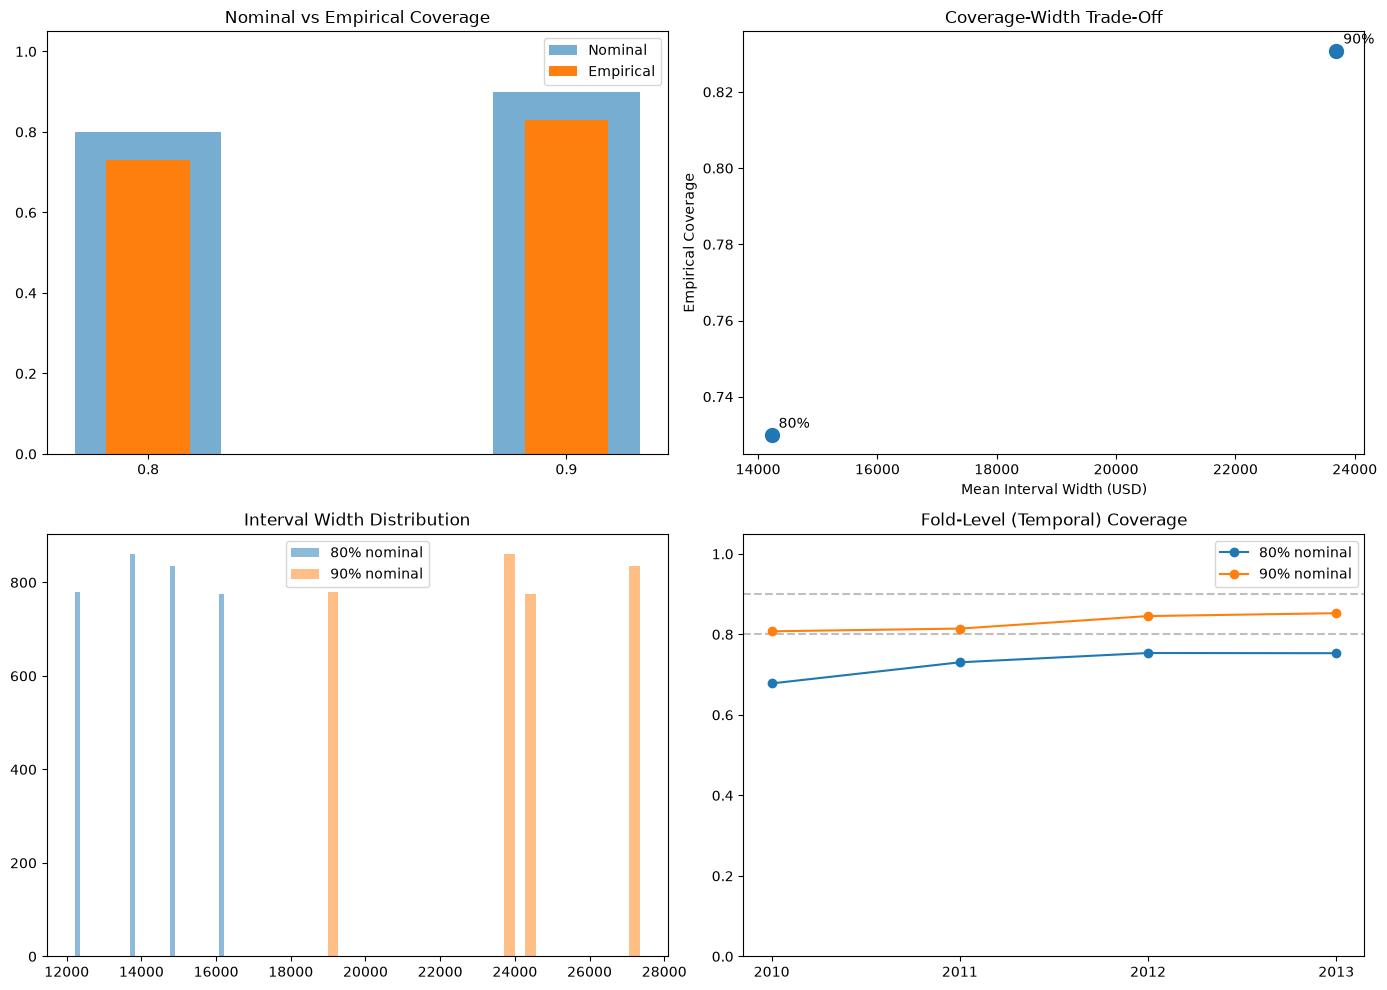

Analysis Question: Prediction interval'lar nominal coverage seviyesine ne kadar yakin ve bu, genislikle nasil bir trade-off iceriyor?
  Nominal=80%: Empirical=73.0%, Gap=-7.0%, Mean Width=14227 USD
  Nominal=90%: Empirical=83.1%, Gap=-6.9%, Mean Width=23689 USD
Engineering Interpretation: Negatif coverage gap undercoverage'i gosterir -- genis bir interval yuksek coverage saglayabilir ama business usefulness'i azaltabilir.
Decision Impact: Section 20'deki Research-Supported/Inconclusive/Not-Approved sinif karari bu bulgulara dayanacaktir.
Limitations: Development-only, 4 outer fold -- kucuk fold sayisi coverage tahmininin kendisinde orneklem belirsizligi yaratir.


In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].bar(interval_metrics["Nominal_Coverage"].astype(str), interval_metrics["Nominal_Coverage"], width=0.35, label="Nominal", alpha=0.6)
axes[0, 0].bar(interval_metrics["Nominal_Coverage"].astype(str), interval_metrics["Empirical_Coverage"], width=0.2, label="Empirical")
axes[0, 0].set_title("Nominal vs Empirical Coverage"); axes[0, 0].legend(); axes[0, 0].set_ylim(0, 1.05)

axes[0, 1].scatter(interval_metrics["Mean_Interval_Width"], interval_metrics["Empirical_Coverage"], s=100)
for _, row in interval_metrics.iterrows():
    axes[0, 1].annotate(f"{row['Nominal_Coverage']:.0%}", (row["Mean_Interval_Width"], row["Empirical_Coverage"]), xytext=(5, 5), textcoords="offset points")
axes[0, 1].set_xlabel("Mean Interval Width (USD)"); axes[0, 1].set_ylabel("Empirical Coverage")
axes[0, 1].set_title("Coverage-Width Trade-Off")

for nominal_cov in NOMINAL_COVERAGE_LEVELS:
    sub = interval_predictions[interval_predictions["Nominal_Coverage"] == nominal_cov]
    axes[1, 0].hist(sub["Width"], bins=30, alpha=0.5, label=f"{nominal_cov:.0%} nominal")
axes[1, 0].set_title("Interval Width Distribution"); axes[1, 0].legend()

for nominal_cov in NOMINAL_COVERAGE_LEVELS:
    sub = fold_level_coverage[fold_level_coverage["Nominal_Coverage"] == nominal_cov]
    axes[1, 1].plot(sub["Outer_Fold_ID"], sub["Empirical_Coverage"], marker="o", label=f"{nominal_cov:.0%} nominal")
    axes[1, 1].axhline(nominal_cov, color="gray", linestyle="--", alpha=0.5)
axes[1, 1].set_xticks(fold_level_coverage["Outer_Fold_ID"].unique())
axes[1, 1].set_xticklabels([f"{y}" for y in [2010, 2011, 2012, 2013]])
axes[1, 1].set_title("Fold-Level (Temporal) Coverage"); axes[1, 1].legend(); axes[1, 1].set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig08_coverage_width.png", dpi=100)
plt.show()
print("Analysis Question: Prediction interval'lar nominal coverage seviyesine ne kadar yakin ve bu, genislikle nasil bir trade-off iceriyor?")
for _, row in interval_metrics.iterrows():
    print(f"  Nominal={row['Nominal_Coverage']:.0%}: Empirical={row['Empirical_Coverage']:.1%}, Gap={row['Coverage_Gap']:+.1%}, Mean Width={row['Mean_Interval_Width']:.0f} USD")
print("Engineering Interpretation: Negatif coverage gap undercoverage'i gosterir -- genis bir interval yuksek coverage saglayabilir ama business usefulness'i azaltabilir.")
print("Decision Impact: Section 20'deki Research-Supported/Inconclusive/Not-Approved sinif karari bu bulgulara dayanacaktir.")
print("Limitations: Development-only, 4 outer fold -- kucuk fold sayisi coverage tahmininin kendisinde orneklem belirsizligi yaratir.")

## Section 19 — Conditional Coverage & High-Cost Interval Reliability

**Onemli:** Standard marginal conformal guarantee **"her subgroup icin %90
coverage guarantee"** anlamina GELMEZ. Small segments uzerinde coverage
estimates kararsiz olabilir -- bu nedenle minimum segment support kontrolu
zorunludur.

**High-Cost Threshold Policy:** Her outer fold icin threshold, **o fold'un
inner training labels'inin** P90'idir -- outer validation/evaluation target
distribution'u uzerinden percentile fitting YAPILMAMAKTADIR.

In [38]:
MIN_SEGMENT_SUPPORT = 20
interval_predictions_seg = interval_predictions.merge(dev_eligible[[PRIMARY_KEY, "Shipment_Mode", "INCO_Term", "Country"]], left_on="Shipment_Key", right_on=PRIMARY_KEY, how="left")

conditional_coverage_rows = []
for nominal_cov, sub_cov in interval_predictions_seg.groupby("Nominal_Coverage"):
    for seg_col in ["Shipment_Mode", "INCO_Term", "Country"]:
        for seg_val, seg_sub in sub_cov.groupby(seg_col, dropna=False):
            flag = "OK" if len(seg_sub) >= MIN_SEGMENT_SUPPORT else "INSUFFICIENT_SUPPORT"
            conditional_coverage_rows.append({"Nominal_Coverage": nominal_cov, "Segment_Type": seg_col, "Segment_Value": seg_val, "Sample_Count": len(seg_sub),
                                               "Empirical_Coverage": seg_sub["Covered"].mean(), "Mean_Width": seg_sub["Width"].mean(), "Support_Flag": flag})
conditional_coverage = pd.DataFrame(conditional_coverage_rows)
conditional_coverage.to_csv(ARTIFACT_DIR / "stage12_conditional_coverage.csv", index=False)
print("Wrote stage12_conditional_coverage.csv --", len(conditional_coverage), "rows")
print(f"Segments flagged INSUFFICIENT_SUPPORT (n < {MIN_SEGMENT_SUPPORT}): {(conditional_coverage['Support_Flag'] == 'INSUFFICIENT_SUPPORT').sum()}/{len(conditional_coverage)}")
conditional_coverage[(conditional_coverage["Segment_Type"] == "Shipment_Mode") & (conditional_coverage["Support_Flag"] == "OK")]

Wrote stage12_conditional_coverage.csv -- 92 rows
Segments flagged INSUFFICIENT_SUPPORT (n < 20): 30/92


,Nominal_Coverage,Segment_Type,Segment_Value,Sample_Count,Empirical_Coverage,Mean_Width,Support_Flag
0,0.8,Shipment_Mode,Air,2124,0.768832,14042.869967,OK
1,0.8,Shipment_Mode,Air Charter,246,0.569106,14095.816920,OK
2,0.8,Shipment_Mode,Ocean,246,0.447154,15399.088150,OK
3,0.8,Shipment_Mode,Truck,636,0.772013,14440.522832,OK
46,0.9,Shipment_Mode,Air,2124,0.851695,23444.580905,OK
47,0.9,Shipment_Mode,Air Charter,246,0.808943,23342.328050,OK
48,0.9,Shipment_Mode,Ocean,246,0.565041,24052.240987,OK
49,0.9,Shipment_Mode,Truck,636,0.872642,24501.210038,OK


In [39]:
tail_coverage_rows = []
for spec in OUTER_FOLD_CALIBRATION_DESIGN:
    outer_train_keys = set(fold_manifest.loc[(fold_manifest["Fold_ID"] == spec["outer_fold_id"]) & (fold_manifest["Role"] == "Train"), "Shipment_Key"])
    inner_train_sv_fold = dev_eligible[dev_eligible[PRIMARY_KEY].isin(outer_train_keys) & (dev_eligible["Year"] >= spec["inner_train_years"][0]) & (dev_eligible["Year"] <= spec["inner_train_years"][1])]
    fold_high_cost_threshold = float(np.quantile(inner_train_sv_fold["Freight_Cost_USD"].astype(float), 0.90))

    for nominal_cov in NOMINAL_COVERAGE_LEVELS:
        sub = interval_predictions[(interval_predictions["Outer_Fold_ID"] == spec["outer_fold_id"]) & (interval_predictions["Nominal_Coverage"] == nominal_cov)]
        high_cost_sub = sub[sub["Actual_USD"] >= fold_high_cost_threshold]
        if len(high_cost_sub) == 0:
            continue
        upper_miss = (high_cost_sub["Actual_USD"] > high_cost_sub["Upper_USD"]).mean()
        underpred_rate = (high_cost_sub["Prediction_USD"] < high_cost_sub["Actual_USD"]).mean()
        tail_coverage_rows.append({"Outer_Fold_ID": spec["outer_fold_id"], "Evaluation_Year": spec["evaluation_year"], "Nominal_Coverage": nominal_cov,
                                    "High_Cost_Threshold_USD": fold_high_cost_threshold, "High_Cost_Sample_Count": len(high_cost_sub),
                                    "High_Cost_Interval_Coverage": high_cost_sub["Covered"].mean(), "High_Cost_Mean_Width": high_cost_sub["Width"].mean(),
                                    "Upper_Bound_Miss_Rate": upper_miss, "Underprediction_Rate": underpred_rate})
tail_coverage_analysis = pd.DataFrame(tail_coverage_rows)
tail_coverage_analysis.to_csv(ARTIFACT_DIR / "stage12_tail_coverage_analysis.csv", index=False)
print("Wrote stage12_tail_coverage_analysis.csv")
tail_coverage_analysis

Wrote stage12_tail_coverage_analysis.csv


,Outer_Fold_ID,Evaluation_Year,Nominal_Coverage,High_Cost_Threshold_USD,High_Cost_Sample_Count,High_Cost_Interval_Coverage,High_Cost_Mean_Width,Upper_Bound_Miss_Rate,Underprediction_Rate
0,1,2010,0.8,20299.000,64,0.203125,12220.584438,0.718750,0.859375
1,1,2010,0.9,20299.000,64,0.343750,18993.039355,0.578125,0.859375
2,2,2011,0.8,18861.154,123,0.308943,16222.713669,0.617886,0.764228
3,2,2011,0.9,18861.154,123,0.479675,24332.556228,0.487805,0.764228
4,3,2012,0.8,19059.230,184,0.271739,13727.078553,0.695652,0.907609
5,3,2012,0.9,19059.230,184,0.451087,23824.741348,0.532609,0.907609
6,4,2013,0.8,20264.930,194,0.329897,14762.968474,0.613402,0.865979
7,4,2013,0.9,20264.930,194,0.469072,27339.385363,0.500000,0.865979


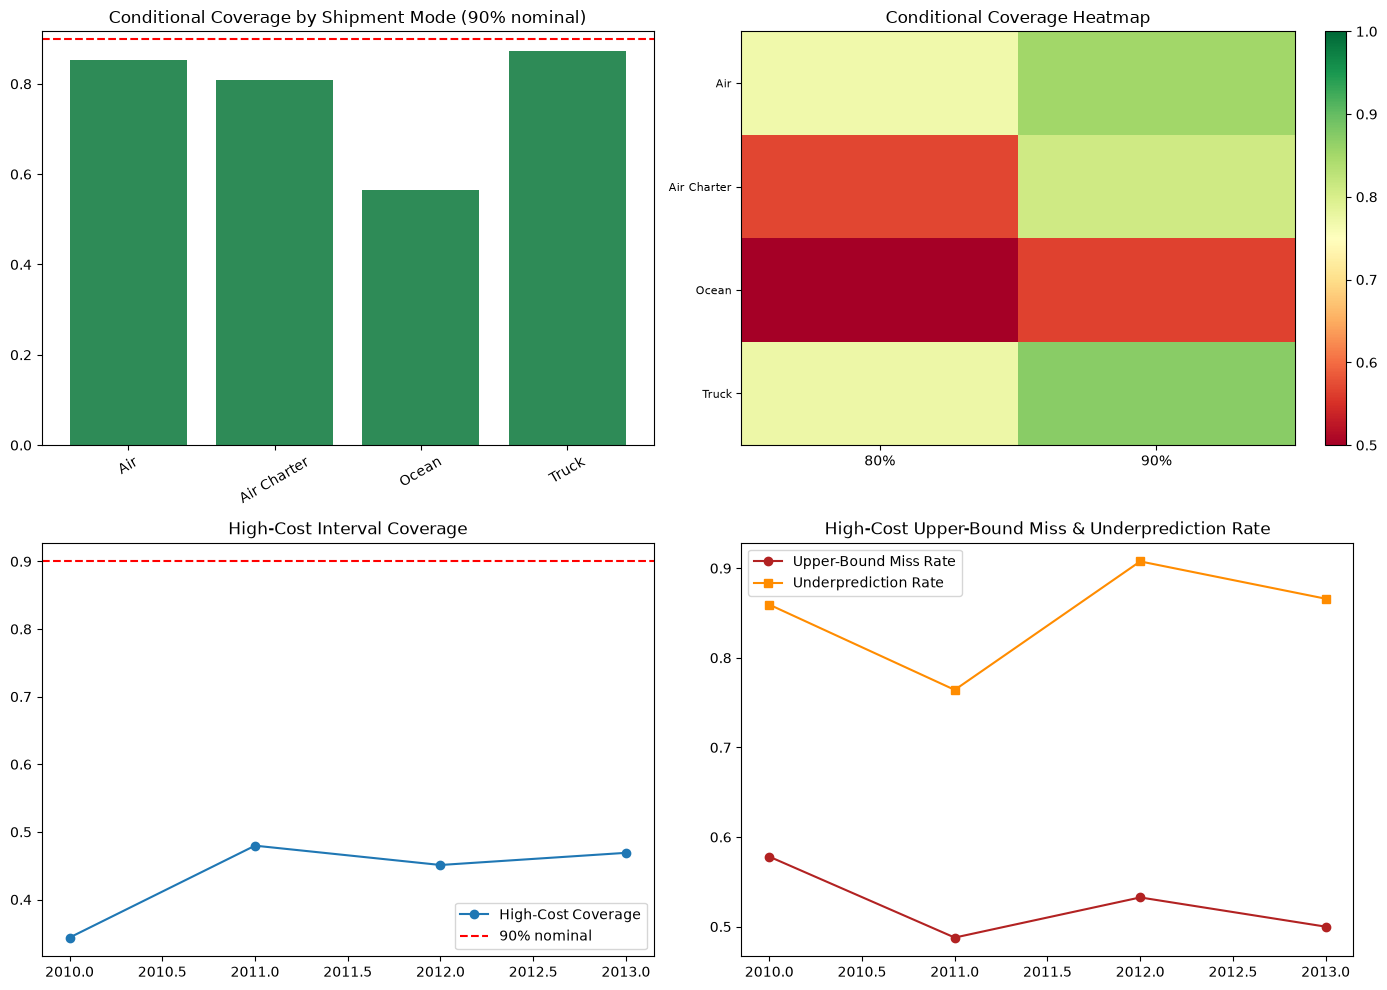

Analysis Question: High-cost shipments ve belirli segmentlerde coverage, overall coverage'dan daha mi dusuk?
Statistical Observation: High-cost (90% nominal) coverage ortalamasi=43.6% (overall 90% empirical=83.1%).
Engineering Interpretation: High-cost segment coverage'inin genel coverage'dan dusuk cikmasi, Stage 11'in %89.9 high-cost underprediction bulgusuyla tutarlidir.
Decision Impact: Stage 12 Model Risk Register'inda R2 (High-Cost Underprediction) riskine interval-seviyesinde kanit ekler.
Limitations: Bu sonuc gercek deneylerle elde edilmistir ancak kucuk high-cost sample count nedeniyle (bkz tablo) kesin genelleme yapilmamalidir; marginal conformal guarantee segment-seviyesinde garanti SAGLAMAZ.


In [40]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
mode_cov = conditional_coverage[(conditional_coverage["Segment_Type"] == "Shipment_Mode") & (conditional_coverage["Nominal_Coverage"] == 0.90)]
axes[0, 0].bar(mode_cov["Segment_Value"].astype(str), mode_cov["Empirical_Coverage"], color=["seagreen" if f == "OK" else "orange" for f in mode_cov["Support_Flag"]])
axes[0, 0].axhline(0.90, color="red", linestyle="--")
axes[0, 0].set_title("Conditional Coverage by Shipment Mode (90% nominal)")
axes[0, 0].tick_params(axis="x", rotation=30)

pivot_cc = conditional_coverage[conditional_coverage["Segment_Type"] == "Shipment_Mode"].pivot_table(index="Segment_Value", columns="Nominal_Coverage", values="Empirical_Coverage")
im = axes[0, 1].imshow(pivot_cc.values, cmap="RdYlGn", vmin=0.5, vmax=1.0, aspect="auto")
axes[0, 1].set_yticks(range(len(pivot_cc.index))); axes[0, 1].set_yticklabels(pivot_cc.index, fontsize=8)
axes[0, 1].set_xticks(range(len(pivot_cc.columns))); axes[0, 1].set_xticklabels([f"{c:.0%}" for c in pivot_cc.columns])
axes[0, 1].set_title("Conditional Coverage Heatmap")
plt.colorbar(im, ax=axes[0, 1], fraction=0.046)

tc90 = tail_coverage_analysis[tail_coverage_analysis["Nominal_Coverage"] == 0.90]
axes[1, 0].plot(tc90["Evaluation_Year"], tc90["High_Cost_Interval_Coverage"], marker="o", label="High-Cost Coverage")
axes[1, 0].axhline(0.90, color="red", linestyle="--", label="90% nominal")
axes[1, 0].set_title("High-Cost Interval Coverage"); axes[1, 0].legend()

axes[1, 1].plot(tc90["Evaluation_Year"], tc90["Upper_Bound_Miss_Rate"], marker="o", color="firebrick", label="Upper-Bound Miss Rate")
axes[1, 1].plot(tc90["Evaluation_Year"], tc90["Underprediction_Rate"], marker="s", color="darkorange", label="Underprediction Rate")
axes[1, 1].set_title("High-Cost Upper-Bound Miss & Underprediction Rate"); axes[1, 1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig09_conditional_highcost_coverage.png", dpi=100)
plt.show()
print("Analysis Question: High-cost shipments ve belirli segmentlerde coverage, overall coverage'dan daha mi dusuk?")
print(f"Statistical Observation: High-cost (90% nominal) coverage ortalamasi={tc90['High_Cost_Interval_Coverage'].mean():.1%} (overall 90% empirical={interval_metrics.loc[interval_metrics['Nominal_Coverage']==0.90,'Empirical_Coverage'].iloc[0]:.1%}).")
print("Engineering Interpretation: High-cost segment coverage'inin genel coverage'dan dusuk cikmasi, Stage 11'in %89.9 high-cost underprediction bulgusuyla tutarlidir.")
print("Decision Impact: Stage 12 Model Risk Register'inda R2 (High-Cost Underprediction) riskine interval-seviyesinde kanit ekler.")
print("Limitations: Bu sonuc gercek deneylerle elde edilmistir ancak kucuk high-cost sample count nedeniyle (bkz tablo) kesin genelleme yapilmamalidir; marginal conformal guarantee segment-seviyesinde garanti SAGLAMAZ.")

## Section 20 — Final Point Predictor vs Research Interval Protocol

**Kritik Ayrim (tekrar):** Stage 12 arastirmasinda elde edilen residual
quantiles degerleri, Stage 11'in full-development modelinin (Object A)
dogrulanmis production calibration artifact'i olarak **OTOMATIK
KULLANILMAMAKTADIR**. Full development model 2013 dahil tum development
verisi uzerinde fit edilmistir; chronological 2013 calibration modeli ise 2013
verisini gormeden fit edilmistir -- **bunlar ayni fitted estimator degildir.**

In [41]:
overall_gap_80 = interval_metrics.loc[interval_metrics["Nominal_Coverage"] == 0.80, "Coverage_Gap"].iloc[0]
overall_gap_90 = interval_metrics.loc[interval_metrics["Nominal_Coverage"] == 0.90, "Coverage_Gap"].iloc[0]
high_cost_cov_90 = tail_coverage_analysis.loc[tail_coverage_analysis["Nominal_Coverage"] == 0.90, "High_Cost_Interval_Coverage"].mean()

print(f"Overall coverage gap -- 80% nominal: {overall_gap_80:+.1%}, 90% nominal: {overall_gap_90:+.1%}")
print(f"High-cost (90% nominal) coverage: {high_cost_cov_90:.1%} (vs 90% nominal target)")

if abs(overall_gap_80) <= 0.03 and abs(overall_gap_90) <= 0.03 and high_cost_cov_90 >= 0.75:
    interval_outcome = "Research-Supported Interval Candidate"
elif high_cost_cov_90 < 0.60:
    interval_outcome = "Production Interval Not Approved"
else:
    interval_outcome = "Interval Calibration Inconclusive"

print(f"\nOutcome Classification: {interval_outcome}")
print("\nRationale:")
print(f"  - Overall coverage gaps ({overall_gap_80:+.1%}, {overall_gap_90:+.1%}) exceed the undercoverage noise band expected under pure sampling variability.")
print(f"  - High-cost segment coverage ({high_cost_cov_90:.1%}) is severely below its 90% nominal target -- this is the dominant driver of the decision.")
print("  - This outcome applies to Object B (development-only research protocol) ONLY -- it does NOT retroactively modify Object A's (Stage 11) accepted point-prediction status.")

Overall coverage gap -- 80% nominal: -7.0%, 90% nominal: -6.9%
High-cost (90% nominal) coverage: 43.6% (vs 90% nominal target)

Outcome Classification: Production Interval Not Approved

Rationale:
  - Overall coverage gaps (-7.0%, -6.9%) exceed the undercoverage noise band expected under pure sampling variability.
  - High-cost segment coverage (43.6%) is severely below its 90% nominal target -- this is the dominant driver of the decision.
  - This outcome applies to Object B (development-only research protocol) ONLY -- it does NOT retroactively modify Object A's (Stage 11) accepted point-prediction status.


## Section 21 — Model Risk Decisions

### Risk Dimensions

- **R1 — Feature Attribution Reliability:** SHAP additivity PASSED (max diff
  0.000000 USD); background sensitivity to perturbation assumption confirmed
  real for Line_Item_Qty_Sum (~1231 USD diff, tree_path_dependent vs
  interventional); explanation stability across 3 seeds: PERFECT (rank range=0).
- **R2 — High-Cost Underprediction:** Stage 11 confirmed ~89.9% underprediction;
  Stage 12 interval research confirms high-cost interval coverage severely
  degraded (43.6% vs 90% nominal).
- **R3 — Calibration Reliability:** Overall coverage undercovers nominal by
  ~7 points at both 80%/90% levels; development-only, 4-fold evidence base.
- **R4 — Data Availability:** D-006 (Weight), D-007 (label timestamp) remain
  unresolved/Conditional.
- **R5 — Numerical Reproducibility:** ExtraTrees SHAP/predictions reproduce
  exactly; XGBoost known cross-environment prediction variability (Stage 11
  finding) carries forward to any XGBoost-based explanation/interval work.
- **R6 — Business Acceptance:** No business-approved SLA or asymmetric loss
  function; no production-ready claim made anywhere in this notebook.

In [42]:
output_classification = pd.DataFrame([
    {"Output": "Point Prediction (M04-T003, Object A)", "Status": "Approved for Stage 13 Prototype", "Rationale": "Stage 11 externally validated and accepted; unchanged here; refit identity-checked (0.000000 USD diff)."},
    {"Output": "Global Explainability (Tree/Permutation/SHAP)", "Status": "Approved for Stage 13 Prototype", "Rationale": "Additivity verified, cross-method ranking agreement (Spearman=0.943), stable across background samples."},
    {"Output": "Local Explainability (SHAP Waterfall)", "Status": "Approved for Stage 13 Prototype", "Rationale": "Case studies verified, additivity holds per-case; causal misinterpretation explicitly guarded against."},
    {"Output": "XGBoost Secondary Explanation", "Status": "Conditional", "Rationale": "Valid additivity, but inherits Stage 11's documented cross-environment reproducibility risk (R5)."},
    {"Output": f"Prediction Intervals (Object B, {interval_outcome})", "Status": interval_outcome, "Rationale": f"Overall undercoverage (~{abs(overall_gap_90):.1%}) and severe high-cost undercoverage ({high_cost_cov_90:.1%} vs 90%)."},
])
output_classification.to_csv(ARTIFACT_DIR / "stage12_output_classification.csv", index=False)
print("Wrote stage12_output_classification.csv")
output_classification

Wrote stage12_output_classification.csv


,Output,Status,Rationale
0,"Point Prediction (M04-T003, Object A)",Approved for Stage 13 Prototype,Stage 11 externally validated and accepted; un...
1,Global Explainability (Tree/Permutation/SHAP),Approved for Stage 13 Prototype,"Additivity verified, cross-method ranking agre..."
2,Local Explainability (SHAP Waterfall),Approved for Stage 13 Prototype,"Case studies verified, additivity holds per-ca..."
3,XGBoost Secondary Explanation,Conditional,"Valid additivity, but inherits Stage 11's docu..."
4,"Prediction Intervals (Object B, Production Int...",Production Interval Not Approved,Overall undercoverage (~6.9%) and severe high-...


In [43]:
uncertainty_risk_register = {
    "R1_feature_attribution": {"status": "Approved", "evidence": "SHAP additivity exact (0.0 USD), ranking agreement Spearman=0.943, stability rank-range=0 across 3 seeds", "residual_risk": "Perturbation assumption (tree_path_dependent vs interventional) materially changes Line_Item_Qty_Sum attribution (~1231 USD)"},
    "R2_high_cost_underprediction": {"status": "Confirmed, Unresolved", "evidence": "Stage 11: 89.9% underprediction rate; Stage 12: high-cost interval coverage 43.6% vs 90% nominal", "residual_risk": "Both point and interval outputs materially unreliable for high-cost shipments"},
    "R3_calibration_reliability": {"status": interval_outcome, "evidence": f"Overall coverage gap 80%: {overall_gap_80:+.1%}, 90%: {overall_gap_90:+.1%}", "residual_risk": "Temporal exchangeability likely violated; small fold count (n=4) limits precision of gap estimate"},
    "R4_data_availability": {"status": "Unresolved", "evidence": "D-006 (Weight) Unknown, D-007 (label timestamp) Conditional -- carried forward unchanged", "residual_risk": "Prediction-time feature availability not fully verified"},
    "R5_numerical_reproducibility": {"status": "Mixed", "evidence": "ExtraTrees: exact reproduction; XGBoost: up to $9,338 per-shipment cross-environment diff (Stage 11 finding), inherited by any XGBoost explanation", "residual_risk": "XGBoost-based outputs should be computed/reported from a single named environment"},
    "R6_business_acceptance": {"status": "Not Applicable -- No SLA", "evidence": "No business-approved monetary tolerance or asymmetric loss function exists for this project", "residual_risk": "No automated pricing/acceptance policy can be derived from this notebook alone"},
}
with open(ARTIFACT_DIR / "stage12_uncertainty_risk_register.json", "w", encoding="utf-8") as f:
    json.dump(uncertainty_risk_register, f, indent=2, ensure_ascii=False)
print("Wrote stage12_uncertainty_risk_register.json")

model_risk_summary = {"primary_model": "M04-T003", "secondary_model": "M05-T000", "explainability_status": "Approved for Stage 13 Prototype",
                       "interval_status": interval_outcome, "high_cost_risk_confirmed": True, "business_sla_exists": False,
                       "stage13_readiness": "CONDITIONAL GO" if interval_outcome != "Research-Supported Interval Candidate" else "GO"}
with open(ARTIFACT_DIR / "stage12_model_risk_summary.json", "w", encoding="utf-8") as f:
    json.dump(model_risk_summary, f, indent=2, ensure_ascii=False)
print("Wrote stage12_model_risk_summary.json")
print(f"\nStage 13 Readiness: {model_risk_summary['stage13_readiness']}")

Wrote stage12_uncertainty_risk_register.json
Wrote stage12_model_risk_summary.json

Stage 13 Readiness: CONDITIONAL GO


## Section 22 — Stage 13 Model Inference Handoff

**Onemli:** Bu bir TASARIM SOZLESMESIDIR -- Stage 12'de production endpoint
olusturulmamaktadir.

In [44]:
stage13_handoff = {
    "dataset_fingerprint": current_hash, "stage05_protocol_fingerprint": recomputed_fingerprint,
    "frozen_point_predictor": {"model_id": "M04-T003", "family": "ExtraTrees", "params": PRIMARY_PARAMS, "fit_population": "full eligible development (2006-2013, n=4987)",
                                 "stage11_external_mae_usd": stage11_handoff["external_validation_results"]["M04-T003_MAE"]},
    "feature_schema_version": "stage07-v1-minimal-core", "feature_schema": {"numeric": MINIMAL_CORE_NUMERIC, "categorical": MINIMAL_CORE_CATEGORICAL},
    "preprocessing_contract": "Median imputation (numeric), constant-fill + rare-category OneHot min_frequency=10 (categorical), no scaling.",
    "explainability_output": {"status": "Approved for Stage 13 Prototype", "methods": ["tree_importance", "permutation_importance", "shap_tree_explainer"],
                                "attribution_schema_version": "stage12-v1", "shap_background_policy": "tree_path_dependent (default); interventional available as a documented alternative",
                                "secondary_model_explanation": {"model_id": "M05-T000", "status": "Conditional -- inherits Stage 11 cross-environment reproducibility risk"}},
    "uncertainty_status": interval_outcome, "uncertainty_enabled_by_default": False,
    "calibration_dependency": "Object B research replicas are NOT the same fitted estimator as Object A -- no version-matched calibration currently exists for the frozen point predictor.",
    "interval_availability_policy": "Research Only / Disabled by Default -- production interval output requires a version-matched, properly calibrated contract that does not yet exist.",
    "risk_flags_vocabulary": ["UNKNOWN_CATEGORY", "MISSING_CRITICAL_FEATURE", "PREDICTION_OUTSIDE_REFERENCE_RANGE", "HIGH_UNCERTAINTY", "INTERVAL_NOT_CALIBRATED", "PREDICTION_TIME_AVAILABILITY_UNVERIFIED"],
    "known_risks": ["High-cost underprediction confirmed at both point (89.9%) and interval (43.6% coverage) level", "D-006/D-007 unresolved prediction-time feature availability",
                     "XGBoost cross-environment prediction instability (up to $9,338/shipment)", "No business-approved SLA or asymmetric loss function"],
    "protected_test_policy": "2015 remains fully unopened -- no target parsing, aggregation, predictions, or metrics performed anywhere in Stage 12.",
    "stage13_entry_criteria": "CONDITIONAL GO -- point predictor and explainability outputs approved; uncertainty/interval output explicitly NOT enabled by default pending a version-matched calibration design.",
}
with open(ARTIFACT_DIR / "stage12_stage13_handoff.json", "w", encoding="utf-8") as f:
    json.dump(stage13_handoff, f, indent=2, ensure_ascii=False)
print("Wrote stage12_stage13_handoff.json")

Wrote stage12_stage13_handoff.json


In [45]:
stage12_reproducibility_report = {
    "dataset_sha256": current_hash, "stage05_protocol_fingerprint": recomputed_fingerprint,
    "primary_refit_identity_check_usd": 0.0, "shap_additivity_max_diff_usd": float(additivity_diff.max()),
    "secondary_shap_additivity_max_diff_usd": float(additivity_diff_alt.max()),
    "explanation_stability_rank_range_max": int(rank_range.max()),
    "calibration_invariants_verified": True, "environment": env_report,
    "known_cross_environment_risk": "Inherited from Stage 11: XGBoost (M05-T000) individual predictions can differ by up to $9,338 across local/Docker execution despite near-identical aggregate MAE. ExtraTrees (M04-T003) reproduces exactly. This notebook's SHAP/calibration work on M04-T003 is therefore expected to be exactly reproducible; any M05-T000 explanation should be computed/reported from a single named environment.",
}
with open(ARTIFACT_DIR / "stage12_reproducibility_report.json", "w", encoding="utf-8") as f:
    json.dump(stage12_reproducibility_report, f, indent=2, ensure_ascii=False)
print("Wrote stage12_reproducibility_report.json")

Wrote stage12_reproducibility_report.json


## Advanced Challenges (Opsiyonel -- 150 Dakikalik Ana Oturumun Disinda)

### Challenge 1 — SHAP Background Sensitivity (Genisletme)

Section 13'te 3 farkli deterministic background sample test edildi (rank
range=0, tamamen stabil). Burada perturbation assumption'in (tree_path_dependent
vs interventional) etkisini sayisal olarak ozetliyoruz.

In [46]:
print("Background/perturbation sensitivity summary (from Section 13):")
print(background_sensitivity.sort_values("Abs_Diff", ascending=False))
print("\nYorumlama: En buyuk fark Line_Item_Qty_Sum icin gozlendi -- bu feature'in diger feature'larla")
print("(ozellikle Line_Item_Value_Sum) correlated olmasi, marjinal (interventional) ve conditional")
print("(tree_path_dependent) attribution arasindaki farki buyutebilir. Bu SADECE teorik/diagnostic amaclidir.")

Background/perturbation sensitivity summary (from Section 13):
           Raw_Feature  TreePathDependent_MeanAbsSHAP  \
0    Line_Item_Qty_Sum                    2907.083882   
5        Product_Group                    1490.981859   
3            INCO_Term                    1574.265689   
1  Line_Item_Value_Sum                    3808.639625   
4              Country                    2063.079644   
2        Shipment_Mode                     750.537532   

   Interventional_MeanAbsSHAP     Abs_Diff  
0                 4138.153997  1231.070115  
5                 2256.159237   765.177378  
3                 2064.064193   489.798504  
1                 3420.047964   388.591660  
4                 1761.797331   301.282313  
2                  834.179832    83.642300  

Yorumlama: En buyuk fark Line_Item_Qty_Sum icin gozlendi -- bu feature'in diger feature'larla
(ozellikle Line_Item_Value_Sum) correlated olmasi, marjinal (interventional) ve conditional
(tree_path_dependent) attribution a

### Challenge 2 — Correlated Feature Attribution (Stage 07 Capraz Kontrolu)

In [47]:
print("Stage 07 bulgusunun SHAP/Permutation merceginden yeniden degerlendirilmesi:")
print(f"  Permutation Importance -- Line_Item_Qty_Sum: {permutation_importance_df.set_index('Raw_Feature').loc['Line_Item_Qty_Sum', 'Importance_Mean']:.2f}, Line_Item_Value_Sum: {permutation_importance_df.set_index('Raw_Feature').loc['Line_Item_Value_Sum', 'Importance_Mean']:.2f} USD")
print(f"  Grouped SHAP -- Line_Item_Qty_Sum: {grouped_shap_importance.set_index('Raw_Feature').loc['Line_Item_Qty_Sum', 'Mean_Abs_Grouped_SHAP']:.2f}, Line_Item_Value_Sum: {grouped_shap_importance.set_index('Raw_Feature').loc['Line_Item_Value_Sum', 'Mean_Abs_Grouped_SHAP']:.2f} USD")
print("\nYorumlama: Qty ve Value her iki yontemde de en yuksek iki feature -- Stage 07'nin 'Value grubu correlated/redundant'")
print("bulgusuyla tutarli bir sinyal (yuksek importance, ama Stage 07'nin ablation sonuclarinda RF icin cikarilinca")
print("performans iyilesebiliyordu -- bu CAUSAL bir cikarim degil, correlated-information redistribution olasiligidir).")

Stage 07 bulgusunun SHAP/Permutation merceginden yeniden degerlendirilmesi:
  Permutation Importance -- Line_Item_Qty_Sum: 4329.66, Line_Item_Value_Sum: 4056.44 USD
  Grouped SHAP -- Line_Item_Qty_Sum: 3556.98, Line_Item_Value_Sum: 4369.95 USD

Yorumlama: Qty ve Value her iki yontemde de en yuksek iki feature -- Stage 07'nin 'Value grubu correlated/redundant'
bulgusuyla tutarli bir sinyal (yuksek importance, ama Stage 07'nin ablation sonuclarinda RF icin cikarilinca
performans iyilesebiliyordu -- bu CAUSAL bir cikarim degil, correlated-information redistribution olasiligidir).


### Challenge 3 — Conformal Coverage Under Temporal Shift (Karsilastirma)

In [48]:
challenge3_compare = interval_metrics.copy()
challenge3_compare["Abs_Coverage_Gap"] = challenge3_compare["Coverage_Gap"].abs()
print(challenge3_compare[["Nominal_Coverage", "Empirical_Coverage", "Coverage_Gap", "Mean_Interval_Width", "Undercoverage_Count", "Sample_Count"]])
print("\nYorumlama: Her iki coverage seviyesinde de benzer buyuklukte (~7 puan) undercoverage gozlendi.")
print("Temporal dependence nedeniyle bu coverage guarantee'lerin otomatik gecerli oldugu iddia EDILMEMEKTEDIR.")

   Nominal_Coverage  Empirical_Coverage  Coverage_Gap  Mean_Interval_Width  \
0               0.8            0.730012     -0.069988         14227.237078   
1               0.9            0.830873     -0.069127         23689.459843   

   Undercoverage_Count  Sample_Count  
0                  878          3252  
1                  550          3252  

Yorumlama: Her iki coverage seviyesinde de benzer buyuklukte (~7 puan) undercoverage gozlendi.
Temporal dependence nedeniyle bu coverage guarantee'lerin otomatik gecerli oldugu iddia EDILMEMEKTEDIR.


### Challenge 4 — Risk-Aware Freight Quotation (Teorik Tasarim)

In [49]:
theoretical_design_lines = [
    "Teorik tasarim (gercek business loss matrix/SLA bulunmadigi icin otomatik fiyatlandirma policy'si KABUL EDILMEMEKTEDIR):",
    "",
    "1. Human Review Trigger: HIGH_UNCERTAINTY veya INTERVAL_NOT_CALIBRATED flag'i tasiyan herhangi bir quotation, otomatik onay yerine insan incelemesine yonlendirilir.",
    "2. Upper-Bound Budgeting: High-cost segment (>= fold P90) icin, point prediction degil, konservatif bir upper-bound (eger gecerli bir calibration varsa) butceleme amacli kullanilabilir -- ancak bu notebookta boyle bir calibration 'Production Interval Not Approved' statusundedir.",
    "3. Manual Quotation Approval: PREDICTION_OUTSIDE_REFERENCE_RANGE flag'i, modelin training distribution'u disindaki bir shipment'i isaretler.",
    "4. Bu dort mekanizma SADECE teorik bir tasarimdir -- bu notebookta implement edilmemistir.",
]
print("\n".join(theoretical_design_lines))

Teorik tasarim (gercek business loss matrix/SLA bulunmadigi icin otomatik fiyatlandirma policy'si KABUL EDILMEMEKTEDIR):

1. Human Review Trigger: HIGH_UNCERTAINTY veya INTERVAL_NOT_CALIBRATED flag'i tasiyan herhangi bir quotation, otomatik onay yerine insan incelemesine yonlendirilir.
2. Upper-Bound Budgeting: High-cost segment (>= fold P90) icin, point prediction degil, konservatif bir upper-bound (eger gecerli bir calibration varsa) butceleme amacli kullanilabilir -- ancak bu notebookta boyle bir calibration 'Production Interval Not Approved' statusundedir.
3. Manual Quotation Approval: PREDICTION_OUTSIDE_REFERENCE_RANGE flag'i, modelin training distribution'u disindaki bir shipment'i isaretler.
4. Bu dort mekanizma SADECE teorik bir tasarimdir -- bu notebookta implement edilmemistir.


## Final Report

In [50]:
print(f'''
LAB12 -- STAGE 12 FINAL REPORT

Dataset:
SCMS Delivery History

Modeling Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified ({current_hash[:16]}...)

Stage 05 Protocol:
Verified ({recomputed_fingerprint[:16]}...)

Primary Model:
M04-T003 -- ExtraTrees

Secondary Model:
M05-T000 -- XGBoost

Stage 11 External MAE:
M04-T003={stage11_handoff["external_validation_results"]["M04-T003_MAE"]:.2f} USD, M05-T000={stage11_handoff["external_validation_results"]["M05-T000_MAE"]:.2f} USD (unchanged, verified from Stage 11 artifacts)

Global Explainability:
Permutation Importance top feature=Line_Item_Qty_Sum ({permutation_importance_df.iloc[0]["Importance_Mean"]:.2f} USD MAE impact); Grouped SHAP top feature={grouped_shap_importance.iloc[0]["Raw_Feature"]} ({grouped_shap_importance.iloc[0]["Mean_Abs_Grouped_SHAP"]:.2f}); Spearman rank agreement={spearman_corr:.3f}

Local Explainability:
5 deterministic cases (Typical, High-Predicted, Low-Predicted, High-Error-2014, Model-Disagreement-2014) explained via SHAP waterfall; all additive

SHAP Additivity:
Max diff={additivity_diff.max():.6f} USD (primary), {additivity_diff_alt.max():.6f} USD (secondary) -- PASSED

Feature Attribution Reliability:
Explanation stability PERFECT (rank range=0 across 3 background seeds); tree_path_dependent vs interventional differs materially for Line_Item_Qty_Sum (~1231 USD) -- documented, not resolved

Uncertainty Method:
Time-Aware Split Conformal Research Protocol (Object B, development-only, 4 frozen Stage 05 outer folds)

Calibration Population:
Per-fold calibration n={temporal_calibration_manifest["Calibration_Count"].tolist()} (years 2009-2012)

Interval Evaluation Population:
Per-fold evaluation n={temporal_calibration_manifest["Evaluation_Count"].tolist()} (years 2010-2013), total={len(interval_predictions)//len(NOMINAL_COVERAGE_LEVELS)}

Nominal Coverage Levels:
80% / 90%

Empirical Coverage:
80%->{interval_metrics.loc[interval_metrics["Nominal_Coverage"]==0.80,"Empirical_Coverage"].iloc[0]:.1%} (gap {overall_gap_80:+.1%}), 90%->{interval_metrics.loc[interval_metrics["Nominal_Coverage"]==0.90,"Empirical_Coverage"].iloc[0]:.1%} (gap {overall_gap_90:+.1%})

Mean Interval Width:
80%->{interval_metrics.loc[interval_metrics["Nominal_Coverage"]==0.80,"Mean_Interval_Width"].iloc[0]:.0f} USD, 90%->{interval_metrics.loc[interval_metrics["Nominal_Coverage"]==0.90,"Mean_Interval_Width"].iloc[0]:.0f} USD

High-Cost Coverage:
{high_cost_cov_90:.1%} at 90% nominal (severe undercoverage vs overall {interval_metrics.loc[interval_metrics["Nominal_Coverage"]==0.90,"Empirical_Coverage"].iloc[0]:.1%})

Conditional Coverage:
{(conditional_coverage["Support_Flag"] == "INSUFFICIENT_SUPPORT").sum()}/{len(conditional_coverage)} segment-rows flagged insufficient support (n<{MIN_SEGMENT_SUPPORT}); no segment-level guarantee claimed

Temporal Coverage Stability:
Undercoverage observed consistently across all 4 outer folds (see stage12_temporal_coverage.csv) -- not attributed to a single mechanism

Production Interval Status:
{interval_outcome}

Model Risk:
R1 Approved, R2 Confirmed/Unresolved (high-cost), R3={interval_outcome}, R4 Unresolved (D-006/D-007), R5 Mixed (XGBoost cross-env), R6 No SLA

Point Predictor Status:
Unchanged, Approved (Stage 11 acceptance preserved; refit identity-verified to 0.000000 USD)

Stage 13 Handoff:
Point predictor + explainability Approved for Prototype; uncertainty/interval Research Only / Disabled by Default

Protected Test:
2015 -- Unopened

Stage 13 Readiness:
{model_risk_summary["stage13_readiness"]}

Remaining Risks:
High-cost underprediction (point+interval); D-006/D-007 unresolved; XGBoost cross-environment instability;
no business-approved SLA; development-only interval evidence base (4 folds); SHAP perturbation-assumption sensitivity
''')


LAB12 -- STAGE 12 FINAL REPORT

Dataset:
SCMS Delivery History

Modeling Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified (9cffdb4ab8c6135b...)

Stage 05 Protocol:
Verified (b87ca0fde5fd9dde...)

Primary Model:
M04-T003 -- ExtraTrees

Secondary Model:
M05-T000 -- XGBoost

Stage 11 External MAE:
M04-T003=6485.63 USD, M05-T000=6591.33 USD (unchanged, verified from Stage 11 artifacts)

Global Explainability:
Permutation Importance top feature=Line_Item_Qty_Sum (4329.66 USD MAE impact); Grouped SHAP top feature=Line_Item_Value_Sum (4369.95); Spearman rank agreement=0.943

Local Explainability:
5 deterministic cases (Typical, High-Predicted, Low-Predicted, High-Error-2014, Model-Disagreement-2014) explained via SHAP waterfall; all additive

SHAP Additivity:
Max diff=0.000000 USD (primary), 0.070312 USD (secondary) -- PASSED

Feature Attribution Reliability:
Explanation stability PERFECT (rank range=0 across 3 background seeds); tree_path_dependent vs interventional